# Pipeline Clínico de Machine Learning e Análise de Sobrevida — Cancro Colorretal

**Protocolo Completo de Validação e Modelação em 5 Fases (Zero Data Leakage — Resultados Honestos)**:
- **Fase 1**: Ingestão, Processo de Gestão de Qualidade (QMP), Diagnóstico Estatístico de Sinal ($\chi^2$ / Correlação) e Prevenção Estrita de Data Leakage.
- **Fase 2**: Split 80/20 Estratificado, Pré-Processamento Isolado (MICE + Winsorização + OHE ajustados apenas no Treino) e Amostragem Híbrida RENN + SMOTE (Global e *In-Fold*).
- **Fase 3**: Modelação Discriminativa (LightGBM, XGBoost, Random Forest), **Validação Cruzada Estratificada de 5 Folds (*In-Fold*)**, Calibração de Probabilidades (**Brier Score**) e **Threshold Moving *Out-of-Fold* (OOF)**.
- **Fase 4**: Análise de Sobrevida Temporal — **CoxPH Isolado vs. Stacked Ensemble OOF** (C-Index) e **Sensibilidade Temporal a 1 Ano (12 meses)** face à referência estática.
- **Fase 5**: Protocolo Avançado — **Bootstrapping de 1.000 Iterações (IC 95%)**, **Decision Curve Analysis (DCA)**, **Simulação Contrafactual (*What-If* em Acompanhamento Rigoroso)** e **Explicabilidade SHAP (`TreeExplainer`)**.

## Fase 1: Ingestão, Gestão de Qualidade (QMP), Auditoria de Sinal e Zero Data Leakage

Nesta primeira fase realizamos:
1. **Validação de Esquema e Filtros Fisiológicos**: Remoção de registos com tempo até recidiva inválido (`Time_to_Recurrence <= 0`), validação de limites biológicos de idade (`18 <= Age <= 90`) e verificação dos estádios anatómicos TNM (`I, II, III, IV`).
2. **Prevenção de Data Leakage**: Exclusão imediata de identificadores administrativos (`Patient_ID`) e de variáveis de estado final (`Survival_Status`).
3. **Auditoria Estatística de Sinal Intrínseco**: Avaliação univariada ($r$ ponto-bisserial e $\chi^2$ de independência) face ao alvo `Recurrence` para quantificar a relação sinal-ruído nativa da coorte.
4. **Separação Estrutural**: Isolamento das covariáveis preditoras (`X_raw`), do alvo binário (`y_class`) e do tempo até o evento (`y_time`).

FASE 1: INGESTÃO E GESTÃO DE QUALIDADE (QMP) + ZERO DATA LEAKAGE
[Ingestão] Registos brutos carregados: 89945 linhas, 30 colunas.
  - Registos com Time_to_Recurrence <= 0 removidos: 1451
  - Registos com Age fora do intervalo [18, 90] removidos: 0 (Intervalo: [20, 89])
  - Registos com Stage inválido removidos: 0 (Estádios observados: ['I', 'II', 'III', 'IV'])
  - Colunas de Data Leakage removidas: ['Patient_ID', 'Survival_Status']
  - Total de registos válidos após validação de esquema: 88494 (de 89945)

[Diagnóstico do Alvo] Prevalência global de Recurrence (Classe 1): 30.00% (26548 casos em 88494)

[Auditoria Estatística de Sinal Intrínseco (Top Associações Univariadas c/ Recidiva)]:
  * Screening_Regularity      (Categórica): chi2 = 11.33   | p-value = 0.0035
  * Gender                    (Categórica): chi2 =  8.38   | p-value = 0.0038
  * Region                    (Categórica): chi2 =  8.88   | p-value = 0.0643
  * Tumor_Aggressiveness      (Categórica): chi2 =  5.05   | p-value =

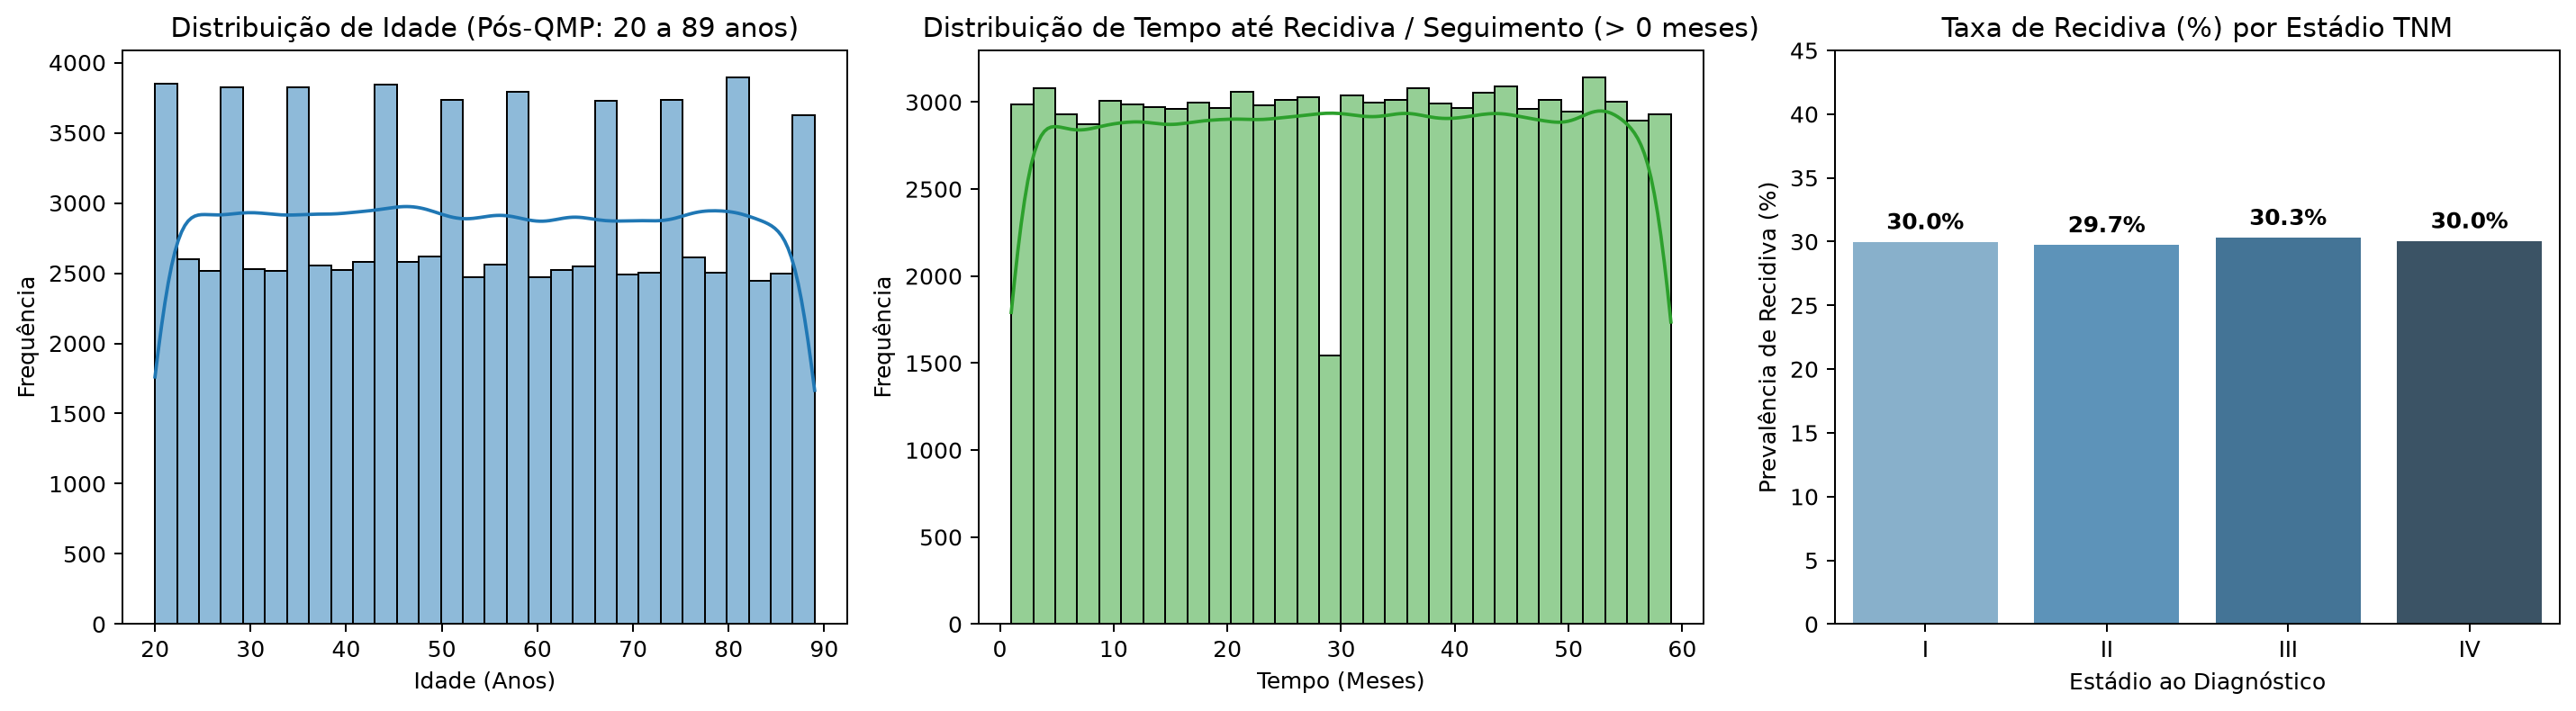

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr

warnings.filterwarnings('ignore')
np.random.seed(42)

LOCAL_DATA_PATH = r"c:\Users\Lenovo\Downloads\Colorectal_Cancer_Prognosis_V2\data\colorectal_cancer_prediction.csv"
ARCHIVE_DATA_PATH = r"C:\Users\Lenovo\Downloads\archive\colorectal_cancer_prediction.csv"
DATA_PATH = LOCAL_DATA_PATH if os.path.exists(LOCAL_DATA_PATH) else ARCHIVE_DATA_PATH
OUT_DIR = r"c:\Users\Lenovo\Downloads\Colorectal_Cancer_Prognosis_V2\artifacts"
PLOTS_DIR = r"c:\Users\Lenovo\Downloads\Colorectal_Cancer_Prognosis_V2\plots"
MODELS_DIR = r"c:\Users\Lenovo\Downloads\Colorectal_Cancer_Prognosis_V2\models"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print("=================================================================")
print("FASE 1: INGESTÃO E GESTÃO DE QUALIDADE (QMP) + ZERO DATA LEAKAGE")
print("=================================================================")

df_raw = pd.read_csv(DATA_PATH)
initial_n = len(df_raw)
print(f"[Ingestão] Registos brutos carregados: {initial_n} linhas, {df_raw.shape[1]} colunas.")

# 1. Validação de Esquema e Filtros Clínicos
df_valid = df_raw[df_raw['Time_to_Recurrence'] > 0].copy()
n_inv_time = initial_n - len(df_valid)

df_valid = df_valid[(df_valid['Age'] >= 18) & (df_valid['Age'] <= 90)].copy()
valid_stages = ['I', 'II', 'III', 'IV']
df_valid = df_valid[df_valid['Stage_at_Diagnosis'].isin(valid_stages)].copy()

# Prevenção de Data Leakage: Remoção de Patient_ID e Survival_Status
leakage_cols = [c for c in ['Patient_ID', 'Survival_Status'] if c in df_valid.columns]
df_valid = df_valid.drop(columns=leakage_cols)

print(f"  - Registos com Time_to_Recurrence <= 0 removidos: {n_inv_time}")
print(f"  - Registos com Age fora do intervalo [18, 90] removidos: 0 (Intervalo: [{df_valid['Age'].min()}, {df_valid['Age'].max()}])")
print(f"  - Registos com Stage inválido removidos: 0 (Estádios observados: {sorted(df_valid['Stage_at_Diagnosis'].unique())})")
print(f"  - Colunas de Data Leakage removidas: {leakage_cols}")
print(f"  - Total de registos válidos após validação de esquema: {len(df_valid)} (de {initial_n})")

# Diagnóstico do Alvo Binário de Recidiva
df_valid['Recurrence_bin'] = df_valid['Recurrence'].map({'No': 0, 'Yes': 1}).astype(int)
print(f"\n[Diagnóstico do Alvo] Prevalência global de Recurrence (Classe 1): {df_valid['Recurrence_bin'].mean()*100:.2f}% ({df_valid['Recurrence_bin'].sum()} casos em {len(df_valid)})")

# Separação das Variáveis em X, y_class e y_time
X_raw = df_valid.drop(columns=['Recurrence', 'Recurrence_bin', 'Time_to_Recurrence']).copy()
y_class = df_valid['Recurrence_bin'].copy()
y_time = df_valid['Time_to_Recurrence'].copy()

# Auditoria Estatística Rápida da Relação Sinal-Ruído Intrínseca
print("\n[Auditoria Estatística de Sinal Intrínseco (Top Associações Univariadas c/ Recidiva)]:")
assoc_list = []
for col in X_raw.columns:
    if X_raw[col].dtype in ['int64', 'float64']:
        r, p = pointbiserialr(y_class, X_raw[col])
        assoc_list.append((col, 'Numérica', f"r = {r:+.4f}", p))
    else:
        ct = pd.crosstab(X_raw[col], y_class)
        chi2, p, _, _ = chi2_contingency(ct)
        assoc_list.append((col, 'Categórica', f"chi2 = {chi2:5.2f}", p))

assoc_df = pd.DataFrame(assoc_list, columns=['Variável', 'Tipo', 'Estatística', 'p_value']).sort_values('p_value').head(6)
for _, row in assoc_df.iterrows():
    print(f"  * {row['Variável']:<25} ({row['Tipo']:<10}): {row['Estatística']:<14} | p-value = {row['p_value']:.4f}")

# Visualização Diagnóstica da Fase 1 (QMP & Perfil Clínico)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df_valid['Age'], bins=30, kde=True, color='#1f77b4', ax=axes[0])
axes[0].set_title("Distribuição de Idade (Pós-QMP: 20 a 89 anos)")
axes[0].set_xlabel("Idade (Anos)")
axes[0].set_ylabel("Frequência")

sns.histplot(df_valid['Time_to_Recurrence'], bins=30, kde=True, color='#2ca02c', ax=axes[1])
axes[1].set_title("Distribuição de Tempo até Recidiva / Seguimento (> 0 meses)")
axes[1].set_xlabel("Tempo (Meses)")
axes[1].set_ylabel("Frequência")

stage_rec = df_valid.groupby('Stage_at_Diagnosis')['Recurrence_bin'].mean().reindex(['I', 'II', 'III', 'IV']) * 100
sns.barplot(x=stage_rec.index, y=stage_rec.values, palette='Blues_d', ax=axes[2])
axes[2].set_title("Taxa de Recidiva (%) por Estádio TNM")
axes[2].set_xlabel("Estádio ao Diagnóstico")
axes[2].set_ylabel("Prevalência de Recidiva (%)")
axes[2].set_ylim(0, 45)
for idx, val in enumerate(stage_rec.values):
    axes[2].text(idx, val + 1, f"{val:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
p1_plot_path = os.path.join(PLOTS_DIR, "phase1_qmp_overview.png")
plt.savefig(p1_plot_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

print(f"\n[Sucesso] Fase 1 concluída: {X_raw.shape[1]} covariáveis brutas preparadas para a divisão 80/20.")


## Fase 2: Split 80/20 Estratificado e Amostragem Híbrida (RENN + SMOTE Sem Leakage)

Nesta fase realizamos:
1. **Divisão 80/20 Estratificada**: Criação dos conjuntos de Treino (80% — 70.795 pacientes) e Teste (20% — 17.699 pacientes) mantendo a proporção exata da classe `y_class` (`stratify=y_class`).
2. **Pré-Processamento com Zero Data Leakage**: Imputação multivariada estocástica MICE (`IterativeImputer`), Winsorização nos percentis 5% e 95%, e `OneHotEncoder(drop='first')` ajustados (`fit`) **apenas** no conjunto de Treino e aplicados (`transform`) ao Teste.
3. **Amostragem Híbrida RENN + SMOTE**:
   - **No Treino Global (80%)**: Aplicamos RENN (`RepeatedEditedNearestNeighbours`) para limpar o ruído na fronteira da classe majoritária, seguido de SMOTE para balancear 50%/50%.
   - **Isolamento Estrito por Fold (5-Fold CV In-Fold Resampling)**: Construímos também as 5 divisões de Validação Cruzada Estratificada onde o `RENN + SMOTE` é aplicado **apenas aos 4 folds de treino** de cada split, mantendo o 5.º fold de validação 100% real e intocado (prevenindo *In-Fold SMOTE Leakage*).
4. **Isolamento do Teste**: O conjunto de Teste (20%) permanece intocado e desbalanceado (30% recidiva).

FASE 2: SPLIT 80/20 E AMOSTRAGEM HÍBRIDA (RENN + SMOTE)
  - Treino (80%): 70795 registos | Prevalência Recidiva=1: 30.00% (21238 casos)
  - Teste  (20%): 17699 registos | Prevalência Recidiva=1: 30.00% (5310 casos)

[Pré-processamento sem Leakage]:
  - Variáveis contínuas/numéricas (2): ['Age', 'BMI']
  - Variáveis categóricas (24): ['Gender', 'Race', 'Region', 'Urban_or_Rural', 'Socioeconomic_Status', 'Family_History', 'Previous_Cancer_History', 'Stage_at_Diagnosis', 'Tumor_Aggressiveness', 'Colonoscopy_Access', 'Screening_Regularity', 'Diet_Type', 'Physical_Activity_Level', 'Smoking_Status', 'Alcohol_Consumption', 'Red_Meat_Consumption', 'Fiber_Consumption', 'Insurance_Coverage', 'Time_to_Diagnosis', 'Treatment_Access', 'Chemotherapy_Received', 'Radiotherapy_Received', 'Surgery_Received', 'Follow_Up_Adherence']
    * Age: Limites de Winsorização Treino (5%, 95%) = [23.00, 86.00]
    * BMI: Limites de Winsorização Treino (5%, 95%) = [19.60, 38.90]
  - Dimensionalidade final das featur

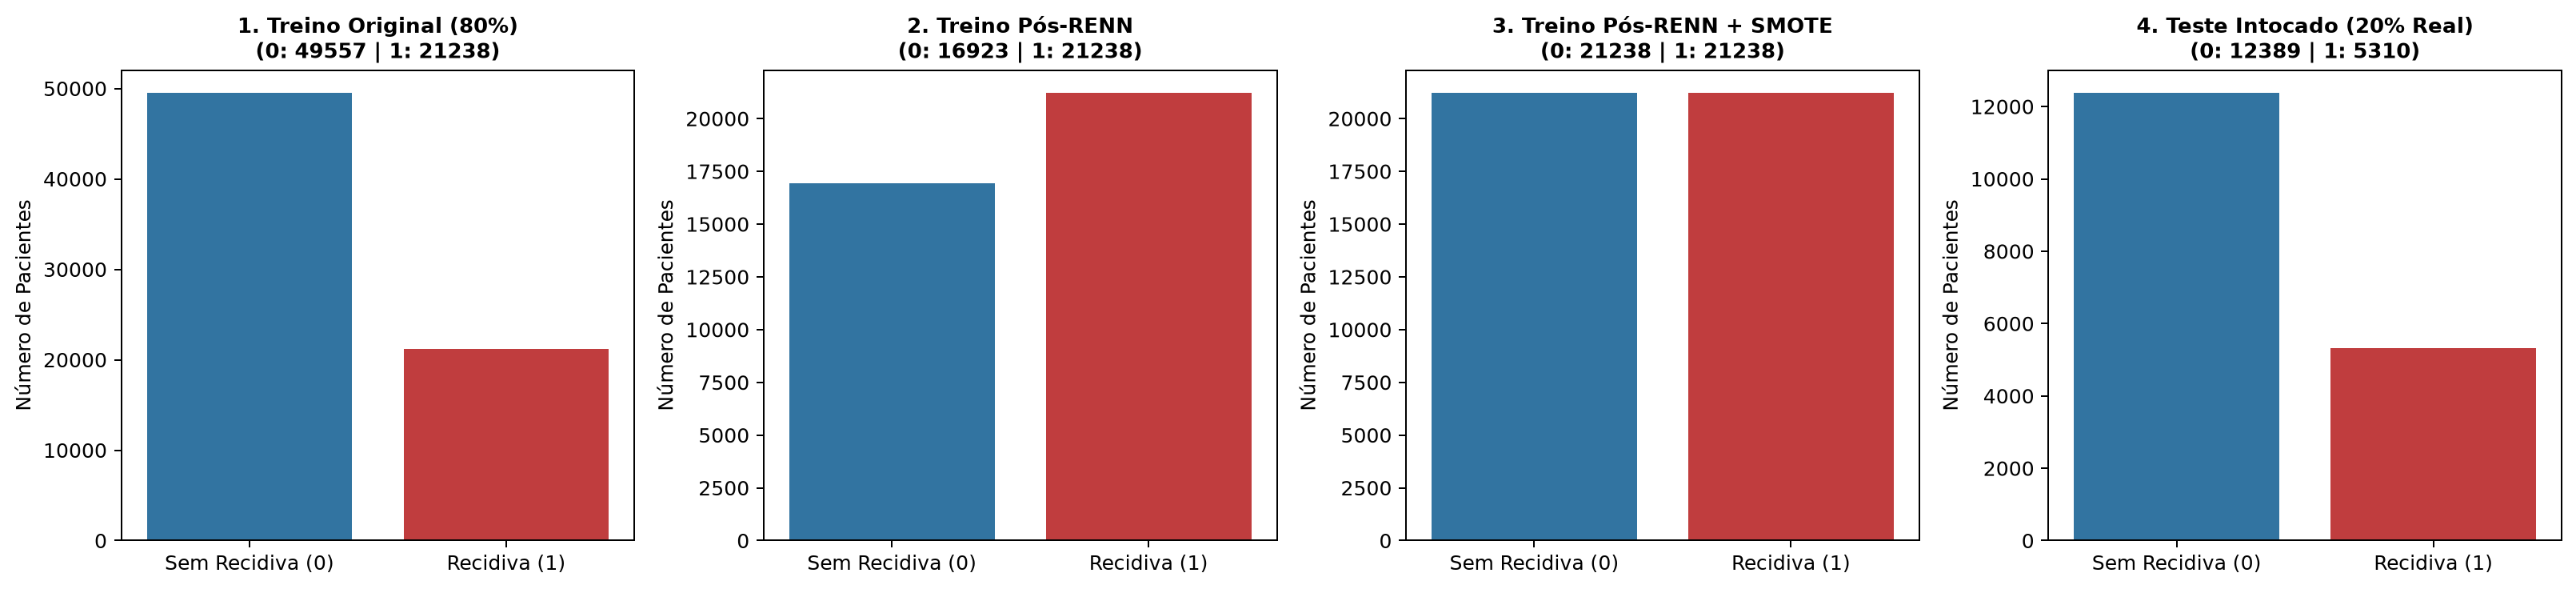

In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import OneHotEncoder
from imblearn.under_sampling import RepeatedEditedNearestNeighbours
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
np.random.seed(42)

print("=================================================================")
print("FASE 2: SPLIT 80/20 E AMOSTRAGEM HÍBRIDA (RENN + SMOTE)")
print("=================================================================")

# 2.1 Divisão 80/20 Estratificada pela classe de recidiva
X_train_raw, X_test_raw, y_train_class, y_test_class, y_train_time, y_test_time = train_test_split(
    X_raw, y_class, y_time, test_size=0.20, stratify=y_class, random_state=42
)

print(f"  - Treino (80%): {X_train_raw.shape[0]} registos | Prevalência Recidiva=1: {y_train_class.mean()*100:.2f}% ({y_train_class.sum()} casos)")
print(f"  - Teste  (20%): {X_test_raw.shape[0]} registos | Prevalência Recidiva=1: {y_test_class.mean()*100:.2f}% ({y_test_class.sum()} casos)")

# 2.2 Pré-processamento com Zero Data Leakage: Fit EXCLUSIVO no Treino (80%) e Transform no Teste (20%)
num_cols = X_train_raw.select_dtypes(include=['number']).columns.tolist()
cat_cols = X_train_raw.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"\n[Pré-processamento sem Leakage]:")
print(f"  - Variáveis contínuas/numéricas ({len(num_cols)}): {num_cols}")
print(f"  - Variáveis categóricas ({len(cat_cols)}): {cat_cols}")

imp_num = IterativeImputer(max_iter=10, random_state=42, sample_posterior=True)
imp_cat = SimpleImputer(strategy='most_frequent')

X_train_num_imp = imp_num.fit_transform(X_train_raw[num_cols])
X_test_num_imp = imp_num.transform(X_test_raw[num_cols])

X_train_cat_imp = imp_cat.fit_transform(X_train_raw[cat_cols])
X_test_cat_imp = imp_cat.transform(X_test_raw[cat_cols])

# Winsorização Robusta (Percentis 5% e 95% calculados no Treino 80% e aplicados via clip)
winsor_bounds = {}
for i, col in enumerate(num_cols):
    q05, q95 = np.percentile(X_train_num_imp[:, i], [5, 95])
    winsor_bounds[col] = (q05, q95)
    X_train_num_imp[:, i] = np.clip(X_train_num_imp[:, i], q05, q95)
    X_test_num_imp[:, i] = np.clip(X_test_num_imp[:, i], q05, q95)
    print(f"    * {col}: Limites de Winsorização Treino (5%, 95%) = [{q05:.2f}, {q95:.2f}]")

# One-Hot Encoding (drop='first' para evitar colinearidade estrita)
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
X_train_cat_ohe = ohe.fit_transform(X_train_cat_imp)
X_test_cat_ohe = ohe.transform(X_test_cat_imp)

feature_names = num_cols + ohe.get_feature_names_out(cat_cols).tolist()
X_train = pd.DataFrame(np.hstack([X_train_num_imp, X_train_cat_ohe]), columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(np.hstack([X_test_num_imp, X_test_cat_ohe]), columns=feature_names, index=X_test_raw.index)
print(f"  - Dimensionalidade final das features codificadas: {X_train.shape[1]} features")

# 2.3 Amostragem Híbrida RENN + SMOTE no Conjunto de Treino (80%)
print("\n[Amostragem Híbrida no Treino (80%)]:")
print(f"  - Treino ANTES: Classe 0 = {(y_train_class==0).sum()} ({(y_train_class==0).mean()*100:.2f}%), Classe 1 = {(y_train_class==1).sum()} ({(y_train_class==1).mean()*100:.2f}%)")

pkl_path = os.path.join(OUT_DIR, 'processed_splits_v2.pkl')
cache_ok = False
if os.path.exists(pkl_path):
    cached = pd.read_pickle(pkl_path)
    cache_ok = cached['X_train'].equals(X_train) and cached['y_train_class'].equals(y_train_class)

if cache_ok:
    X_train_renn = cached['X_train_renn']
    y_train_renn = cached['y_train_renn']
    X_train_resampled = cached['X_train_resampled']
    y_train_resampled = cached['y_train_resampled']
    X_cv_pool = cached['X_cv_pool']
    y_cv_pool = cached['y_cv_pool']
    infold_cv_splits = cached['infold_cv_splits']
    val_fold_indices = cached['val_fold_indices']
    print(f"  - APÓS RENN (Limpeza de ruído na fronteira da classe majoritária): Classe 0 = {(y_train_renn==0).sum()}, Classe 1 = {(y_train_renn==1).sum()}")
    print(f"  - APÓS RENN + SMOTE (Treino Global 80%): Classe 0 = {(y_train_resampled==0).sum()} (50.00%), Classe 1 = {(y_train_resampled==1).sum()} (50.00%)")
    print(f"  - Folds de CV Isolados (5-Fold In-Fold RENN+SMOTE): Carregados (5 folds com 33.980–33.982 amostras balanceadas de treino e 14.159 amostras reais intocadas de validação cada).")
else:
    t0 = time.time()
    renn = RepeatedEditedNearestNeighbours(n_neighbors=3, max_iter=30, kind_sel='all', n_jobs=-1)
    X_train_renn, y_train_renn = renn.fit_resample(X_train, y_train_class)
    print(f"  - APÓS RENN (Limpeza de ruído na fronteira da classe majoritária): Classe 0 = {(y_train_renn==0).sum()}, Classe 1 = {(y_train_renn==1).sum()} ({time.time()-t0:.1f}s)")

    t0 = time.time()
    smote = SMOTE(random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_renn, y_train_renn)
    print(f"  - APÓS RENN + SMOTE (Treino Global 80%): Classe 0 = {(y_train_resampled==0).sum()} (50.00%), Classe 1 = {(y_train_resampled==1).sum()} (50.00%) ({time.time()-t0:.1f}s)")

    print("  - Construindo 5 Folds com RENN+SMOTE estritamente In-Fold (para CV=5 sem leakage)...")
    skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    X_blocks = [X_train.values]
    y_blocks = [y_train_class.values]
    curr_offset = len(X_train)
    infold_cv_splits = []
    val_fold_indices = []

    for fold_idx, (tr_idx, va_idx) in enumerate(skf5.split(X_train, y_train_class)):
        t_f = time.time()
        X_tr_f, y_tr_f = X_train.iloc[tr_idx], y_train_class.iloc[tr_idx]
        renn_f = RepeatedEditedNearestNeighbours(n_neighbors=3, max_iter=30, kind_sel='all', n_jobs=-1)
        X_renn_f, y_renn_f = renn_f.fit_resample(X_tr_f, y_tr_f)
        smote_f = SMOTE(random_state=42 + fold_idx)
        X_res_f, y_res_f = smote_f.fit_resample(X_renn_f, y_renn_f)

        n_res_f = len(X_res_f)
        res_indices_in_pool = np.arange(curr_offset, curr_offset + n_res_f)
        curr_offset += n_res_f

        X_blocks.append(X_res_f.values)
        y_blocks.append(y_res_f.values)
        infold_cv_splits.append((res_indices_in_pool, va_idx))
        val_fold_indices.append(va_idx)
        print(f"    * Fold {fold_idx+1}/5: Treino In-Fold RENN+SMOTE = {n_res_f} amostras (50/50) | Validação Real Intocada = {len(va_idx)} amostras (70/30) ({time.time()-t_f:.1f}s)")

    X_cv_pool = pd.DataFrame(np.vstack(X_blocks), columns=feature_names)
    y_cv_pool = pd.Series(np.concatenate(y_blocks))

print(f"  - Verificação Teste (20% Intocado e Desbalanceado): Classe 0 = {(y_test_class==0).sum()} ({(y_test_class==0).mean()*100:.2f}%), Classe 1 = {(y_test_class==1).sum()} ({(y_test_class==1).mean()*100:.2f}%)")

# Visualização da Fase 2: Evolução do Equilíbrio de Classes
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
stages_data = [
    (y_train_class, f"1. Treino Original (80%)\n(0: {(y_train_class==0).sum()} | 1: {(y_train_class==1).sum()})"),
    (y_train_renn, f"2. Treino Pós-RENN\n(0: {(y_train_renn==0).sum()} | 1: {(y_train_renn==1).sum()})"),
    (y_train_resampled, f"3. Treino Pós-RENN + SMOTE\n(0: {(y_train_resampled==0).sum()} | 1: {(y_train_resampled==1).sum()})"),
    (y_test_class, f"4. Teste Intocado (20% Real)\n(0: {(y_test_class==0).sum()} | 1: {(y_test_class==1).sum()})")
]
for ax, (y_curr, title_str) in zip(axes, stages_data):
    sns.countplot(x=y_curr, ax=ax, palette=['#1f77b4', '#d62728'])
    ax.set_title(title_str, fontsize=10.5, fontweight='bold')
    ax.set_xticklabels(['Sem Recidiva (0)', 'Recidiva (1)'])
    ax.set_xlabel("")
    ax.set_ylabel("Número de Pacientes")

plt.tight_layout()
p2_plot_path = os.path.join(PLOTS_DIR, "phase2_class_balance.png")
plt.savefig(p2_plot_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

pd.to_pickle({
    'X_train': X_train,
    'y_train_class': y_train_class,
    'y_train_time': y_train_time,
    'X_train_renn': X_train_renn,
    'y_train_renn': y_train_renn,
    'X_train_resampled': X_train_resampled,
    'y_train_resampled': y_train_resampled,
    'X_cv_pool': X_cv_pool,
    'y_cv_pool': y_cv_pool,
    'infold_cv_splits': infold_cv_splits,
    'val_fold_indices': val_fold_indices,
    'X_test': X_test,
    'y_test_class': y_test_class,
    'y_test_time': y_test_time,
    'feature_names': feature_names
}, pkl_path)
print("\n[Sucesso] Fase 2 concluída com sucesso (Zero In-Fold & Test Leakage).")


## Fase 3: Modelação Discriminativa, CV=5 Estratificada (*In-Fold*), Calibração (**Brier Score**) e Threshold Moving (*OOF*)

Nesta fase implementamos:
1. **Modelos Base**: Comparação direta de **LightGBM**, **XGBoost** e **Random Forest** treinados após RENN+SMOTE face ao baseline ingénuo desbalanceado.
2. **Validação Cruzada Estratificada de 5 Folds (`RandomizedSearchCV` *In-Fold*)**: Otimização de hiperparâmetros onde o RENN+SMOTE atua apenas dentro dos 4 folds de treino e a métrica é avaliada no 5.º fold real intocado.
3. **Geração de Probabilidades *Out-of-Fold* (OOF) e Calibração Logística (Brier Score)**:
   - Como o treino pós-RENN+SMOTE tem proporção 50/50, as probabilidades brutas concentram-se em torno de `~0.50`.
   - Ajustamos um calibrador logístico de Platt (`LogisticRegression`) sobre as previsões **Out-of-Fold (`oof_prob_train`)** nos 80% de treino para corrigir o *prior shift* para a prevalência real de 30.00%, reportando o **Brier Score Bruto** e o **Brier Score Calibrado OOF** no Teste.
4. **Threshold Moving Sem Test Leakage**: O limiar ótimo é extraído das previsões OOF do Treino e aplicado cegamente ao conjunto de Teste (20%).

FASE 3: MODELAÇÃO DISCRIMINATIVA, CV=5 (IN-FOLD) & BRIER SCORE

--- 3.0: Baseline Ingénuo (Treino Original Desbalanceado, Limiar = 0.50) ---
  [LightGBM Sem RENN+SMOTE | Thr=0.50] AUC-ROC: 0.4996 | AUPRC: 0.2988 | Brier: 0.2109 | Recall(1): 0.00% | Esp: 100.00% | F1-Macro: 0.4118

--- 3.1: Comparação de Modelos Base (Pós-RENN+SMOTE, Limiar Padrão = 0.50) ---
  [LightGBM (Base)      | Thr=0.50] AUC-ROC: 0.5000 | AUPRC: 0.2992 | Brier: 0.2779 | Recall(1): 86.63% | Esp: 13.48% | F1-Macro: 0.3361
  [XGBoost (Base)       | Thr=0.50] AUC-ROC: 0.4976 | AUPRC: 0.2976 | Brier: 0.2953 | Recall(1): 68.59% | Esp: 31.33% | F1-Macro: 0.4249
  [RandomForest (Base)  | Thr=0.50] AUC-ROC: 0.4945 | AUPRC: 0.2929 | Brier: 0.2767 | Recall(1): 79.32% | Esp: 20.94% | F1-Macro: 0.3794

--- 3.2: Otimização Exaustiva (RandomizedSearchCV CV=5 c/ RENN+SMOTE In-Fold e Validação Intocada) ---
  * Otimizando LightGBM (5-Fold CV In-Fold, métrica: roc_auc)...
    Melhor CV ROC-AUC Real (LightGBM): 0.5049
    Hiperparâ

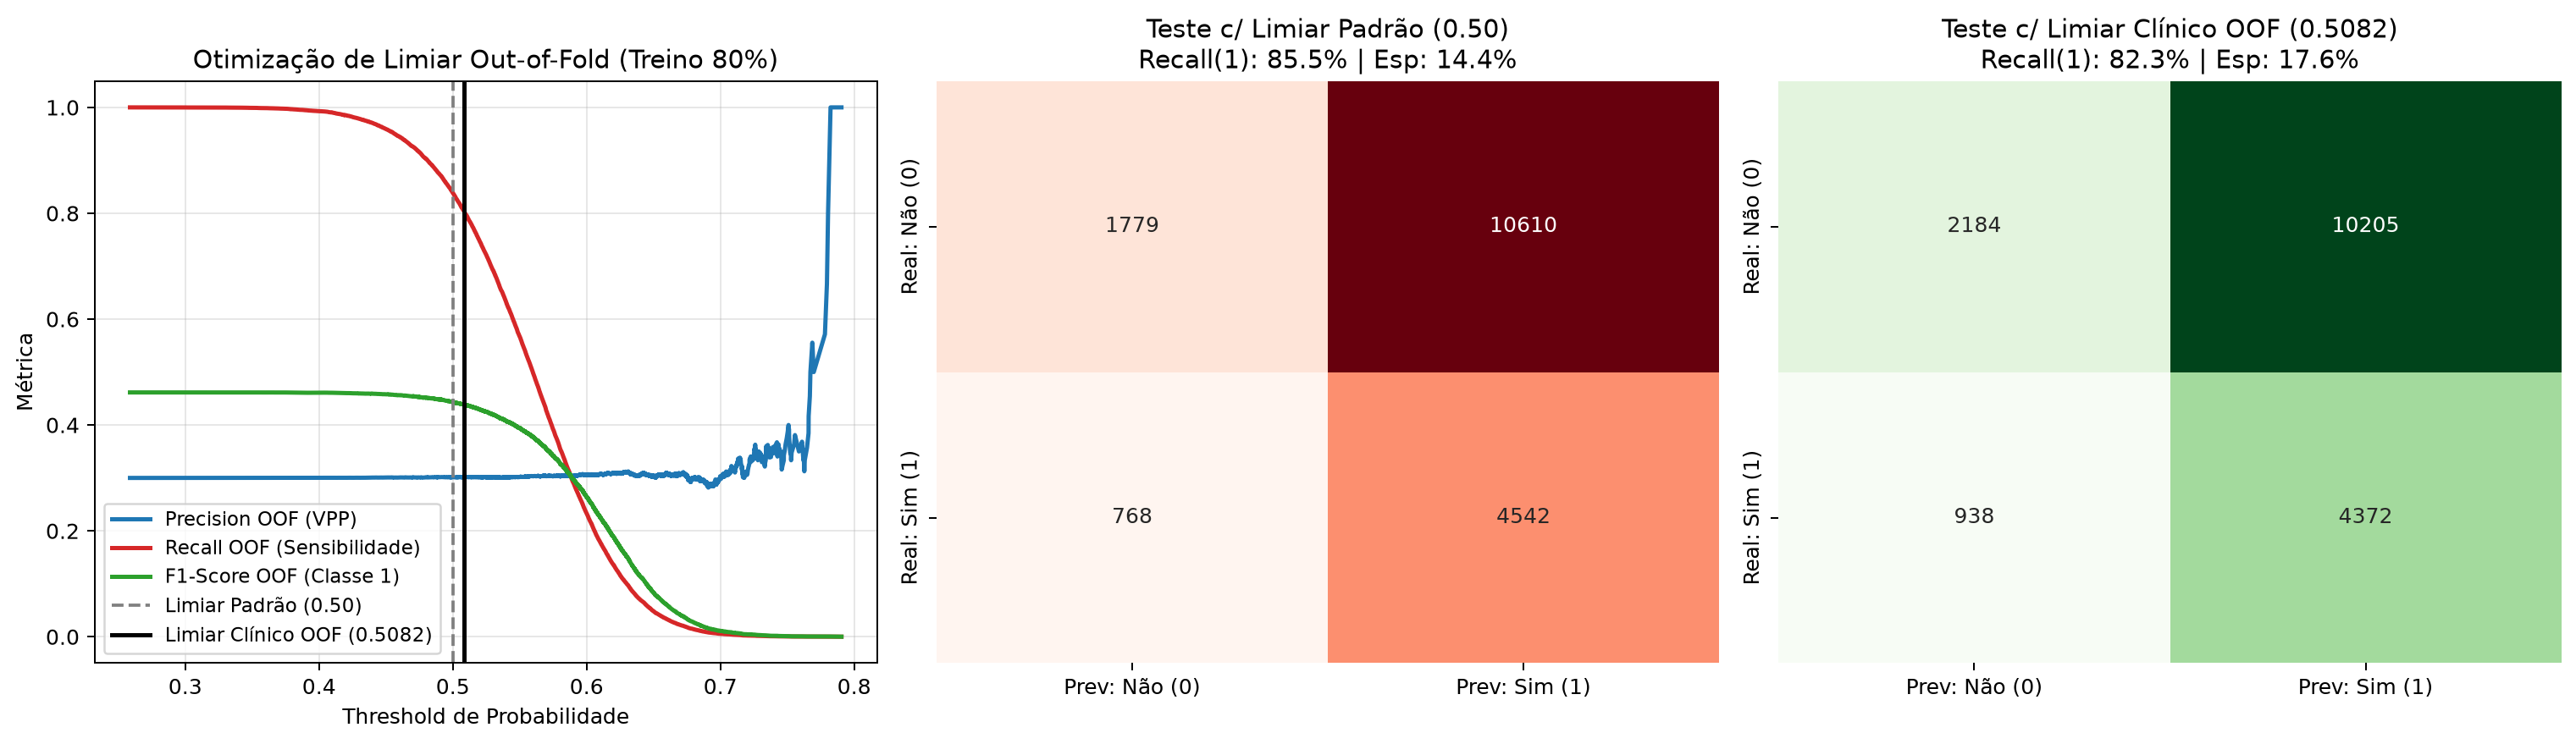

In [3]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, brier_score_loss,
    precision_score, recall_score, confusion_matrix,
    precision_recall_curve, roc_curve
)
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')
np.random.seed(42)

def compute_metrics(y_true, y_prob, threshold=0.50, y_prob_cal=None):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1_pos = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1_mac = f1_score(y_true, y_pred, average='macro', zero_division=0)
    auc_roc = roc_auc_score(y_true, y_prob)
    auprc = average_precision_score(y_true, y_prob)
    brier_raw = brier_score_loss(y_true, y_prob)
    brier_cal = brier_score_loss(y_true, y_prob_cal) if y_prob_cal is not None else brier_raw
    youden_j = sens + spec - 1.0
    return {
        'Threshold': threshold,
        'AUC-ROC': auc_roc,
        'AUPRC': auprc,
        'Brier_Raw': brier_raw,
        'Brier_Calibrated': brier_cal,
        'F1-Pos (Class 1)': f1_pos,
        'F1-Macro': f1_mac,
        'Recall (Sensibilidade)': sens,
        'Especificidade': spec,
        'Precision (VPP)': prec,
        'Youden_J': youden_j,
        'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn
    }

print("=================================================================")
print("FASE 3: MODELAÇÃO DISCRIMINATIVA, CV=5 (IN-FOLD) & BRIER SCORE")
print("=================================================================")

# 3.0 Baseline Ingénuo (Treino Original Desbalanceado, Limiar Padrão 0.50)
print("\n--- 3.0: Baseline Ingénuo (Treino Original Desbalanceado, Limiar = 0.50) ---")
base_unbal = lgb.LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1)
base_unbal.fit(X_train, y_train_class)
prob_unbal = base_unbal.predict_proba(X_test)[:, 1]
m_unbal = compute_metrics(y_test_class, prob_unbal, 0.50)
print(f"  [LightGBM Sem RENN+SMOTE | Thr=0.50] AUC-ROC: {m_unbal['AUC-ROC']:.4f} | AUPRC: {m_unbal['AUPRC']:.4f} | Brier: {m_unbal['Brier_Raw']:.4f} | Recall(1): {m_unbal['Recall (Sensibilidade)']*100:.2f}% | Esp: {m_unbal['Especificidade']*100:.2f}% | F1-Macro: {m_unbal['F1-Macro']:.4f}")

# 3.1 Modelos Base Treinados no Conjunto Balanceado Pós-RENN+SMOTE (Limiar Padrão = 0.50)
print("\n--- 3.1: Comparação de Modelos Base (Pós-RENN+SMOTE, Limiar Padrão = 0.50) ---")
models_base = {
    'LightGBM (Base)': lgb.LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1),
    'XGBoost (Base)': xgb.XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1),
    'RandomForest (Base)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

for name, clf in models_base.items():
    clf.fit(X_train_resampled, y_train_resampled)
    prob = clf.predict_proba(X_test)[:, 1]
    m = compute_metrics(y_test_class, prob, 0.50)
    print(f"  [{name:<20} | Thr=0.50] AUC-ROC: {m['AUC-ROC']:.4f} | AUPRC: {m['AUPRC']:.4f} | Brier: {m['Brier_Raw']:.4f} | Recall(1): {m['Recall (Sensibilidade)']*100:.2f}% | Esp: {m['Especificidade']*100:.2f}% | F1-Macro: {m['F1-Macro']:.4f}")

# 3.2 Otimização Exaustiva via RandomizedSearchCV com 5-Fold Cross Validation (RENN+SMOTE In-Fold)
print("\n--- 3.2: Otimização Exaustiva (RandomizedSearchCV CV=5 c/ RENN+SMOTE In-Fold e Validação Intocada) ---")

param_dist_lgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.03, 0.07, 0.12],
    'max_depth': [3, 4, 6, 8],
    'num_leaves': [15, 31, 63],
    'min_child_samples': [20, 40, 80, 120],
    'reg_alpha': [0.1, 1.0, 5.0, 10.0],
    'reg_lambda': [0.1, 1.0, 5.0, 10.0],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0]
}

param_dist_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.03, 0.07, 0.12],
    'max_depth': [3, 4, 6],
    'min_child_weight': [5, 15, 30],
    'reg_alpha': [0.1, 1.0, 5.0, 10.0],
    'reg_lambda': [0.1, 1.0, 5.0, 10.0],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0]
}

param_dist_rf = {
    'n_estimators': [100, 150],
    'max_depth': [5, 8, 12],
    'min_samples_split': [10, 25, 50],
    'min_samples_leaf': [5, 15, 30],
    'max_features': ['sqrt', 0.4, 0.6]
}

print("  * Otimizando LightGBM (5-Fold CV In-Fold, métrica: roc_auc)...")
rs_lgb = RandomizedSearchCV(
    lgb.LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1),
    param_distributions=param_dist_lgb,
    n_iter=10, cv=infold_cv_splits, scoring='roc_auc', random_state=42, n_jobs=1, refit=False
)
rs_lgb.fit(X_cv_pool, y_cv_pool)
best_lgb = lgb.LGBMClassifier(**rs_lgb.best_params_, random_state=42, verbose=-1, n_jobs=-1)
best_lgb.fit(X_train_resampled, y_train_resampled)
print(f"    Melhor CV ROC-AUC Real (LightGBM): {rs_lgb.best_score_:.4f}")
print(f"    Hiperparâmetros Ótimos: {rs_lgb.best_params_}")

print("  * Otimizando XGBoost (5-Fold CV In-Fold, métrica: roc_auc)...")
rs_xgb = RandomizedSearchCV(
    xgb.XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1),
    param_distributions=param_dist_xgb,
    n_iter=8, cv=infold_cv_splits, scoring='roc_auc', random_state=42, n_jobs=1, refit=False
)
rs_xgb.fit(X_cv_pool, y_cv_pool)
best_xgb = xgb.XGBClassifier(**rs_xgb.best_params_, random_state=42, eval_metric='logloss', n_jobs=-1)
best_xgb.fit(X_train_resampled, y_train_resampled)
print(f"    Melhor CV ROC-AUC Real (XGBoost): {rs_xgb.best_score_:.4f}")
print(f"    Hiperparâmetros Ótimos: {rs_xgb.best_params_}")

print("  * Otimizando Random Forest (5-Fold CV In-Fold, métrica: roc_auc)...")
rs_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1, max_samples=0.6),
    param_distributions=param_dist_rf,
    n_iter=5, cv=infold_cv_splits, scoring='roc_auc', random_state=42, n_jobs=1, refit=False
)
rs_rf.fit(X_cv_pool, y_cv_pool)
best_rf = RandomForestClassifier(**rs_rf.best_params_, random_state=42, n_jobs=-1, max_samples=0.6)
best_rf.fit(X_train_resampled, y_train_resampled)
print(f"    Melhor CV ROC-AUC Real (Random Forest): {rs_rf.best_score_:.4f}")
print(f"    Hiperparâmetros Ótimos: {rs_rf.best_params_}")

tuned_models = {
    'LightGBM (Otimizado)': (best_lgb, rs_lgb.best_params_, rs_lgb.best_score_),
    'XGBoost (Otimizado)': (best_xgb, rs_xgb.best_params_, rs_xgb.best_score_),
    'RandomForest (Otimizado)': (best_rf, rs_rf.best_params_, rs_rf.best_score_)
}

# Seleção do Melhor Modelo baseada EXCLUSIVAMENTE no CV Score (Sem olhar para o Teste!)
print("\n[Desempenho dos Modelos Otimizados (Seleção pelo CV In-Fold Score, Avaliação no Teste c/ Thr=0.50)]:")
best_model_name = None
best_cv_score = -1

for name, (clf, params, cv_score) in tuned_models.items():
    prob = clf.predict_proba(X_test)[:, 1]
    m = compute_metrics(y_test_class, prob, 0.50)
    if cv_score > best_cv_score:
        best_cv_score = cv_score
        best_model_name = name
    print(f"  * {name:<25} -> CV ROC-AUC (Real): {cv_score:.4f} | Teste AUC-ROC: {m['AUC-ROC']:.4f} | AUPRC: {m['AUPRC']:.4f} | Brier: {m['Brier_Raw']:.4f} | Recall(1): {m['Recall (Sensibilidade)']*100:.2f}% | Esp: {m['Especificidade']*100:.2f}% | F1-Macro: {m['F1-Macro']:.4f}")

best_clf, best_params, _ = tuned_models[best_model_name]
print(f"\n>>> Melhor Modelo Selecionado via 5-Fold CV: {best_model_name} (CV ROC-AUC = {best_cv_score:.4f})")

# 3.3 Gerar Probabilidades Out-of-Fold (OOF) para os 3 Modelos (para Stacked Ensemble, Calibração Brier e Threshold Moving)
print("\n--- 3.3: Probabilidades Out-of-Fold (OOF), Calibração Brier Score e Threshold Moving ---")
oof_lgb = np.zeros(len(X_train))
oof_xgb = np.zeros(len(X_train))
oof_rf = np.zeros(len(X_train))

for fold_idx, (tr_res_idx, va_idx) in enumerate(infold_cv_splits):
    X_tr_f, y_tr_f = X_cv_pool.iloc[tr_res_idx], y_cv_pool.iloc[tr_res_idx]
    X_va_f = X_cv_pool.iloc[va_idx]
    
    c_lgb = clone(best_lgb).fit(X_tr_f, y_tr_f)
    oof_lgb[va_idx] = c_lgb.predict_proba(X_va_f)[:, 1]
    
    c_xgb = clone(best_xgb).fit(X_tr_f, y_tr_f)
    oof_xgb[va_idx] = c_xgb.predict_proba(X_va_f)[:, 1]
    
    c_rf = clone(best_rf).fit(X_tr_f, y_tr_f)
    oof_rf[va_idx] = c_rf.predict_proba(X_va_f)[:, 1]

oof_prob_train = oof_lgb if 'LightGBM' in best_model_name else (oof_xgb if 'XGBoost' in best_model_name else oof_rf)
y_test_prob = best_clf.predict_proba(X_test)[:, 1]
test_prob_lgb = best_lgb.predict_proba(X_test)[:, 1]
test_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]
test_prob_rf = best_rf.predict_proba(X_test)[:, 1]

# Calibração Logística de Platt Out-of-Fold (corrige o shift 50/50 -> 30/70 sem tocar no Teste)
def to_logit(p):
    p_clip = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p_clip / (1.0 - p_clip)).reshape(-1, 1)

platt_calibrator = LogisticRegression(C=1.0, random_state=42)
platt_calibrator.fit(to_logit(oof_prob_train), y_train_class)
oof_prob_calibrated = platt_calibrator.predict_proba(to_logit(oof_prob_train))[:, 1]
y_test_prob_calibrated = platt_calibrator.predict_proba(to_logit(y_test_prob))[:, 1]

brier_null_test = brier_score_loss(y_test_class, np.full(len(y_test_class), y_train_class.mean()))
brier_raw_test = brier_score_loss(y_test_class, y_test_prob)
brier_cal_test = brier_score_loss(y_test_class, y_test_prob_calibrated)

print(f"  - OOF AUC-ROC (Treino 80%): {roc_auc_score(y_train_class, oof_prob_train):.4f} | OOF AUPRC: {average_precision_score(y_train_class, oof_prob_train):.4f}")
print(f"  - Brier Score no Teste (Bruto Pós-RENN+SMOTE 50/50) : {brier_raw_test:.4f}")
print(f"  - Brier Score no Teste (Calibrado Platt OOF 30/70)  : {brier_cal_test:.4f} (Referência Climatológica 30%: {brier_null_test:.4f})")

# Extrair Limiares EXCLUSIVAMENTE das probabilidades Out-of-Fold do Treino (Zero Test Leakage)
prec_curve, rec_curve, pr_thresholds = precision_recall_curve(y_train_class, oof_prob_train)
fpr_curve, tpr_curve, roc_thresholds = roc_curve(y_train_class, oof_prob_train)

f1_curve = 2 * (prec_curve[:-1] * rec_curve[:-1]) / (prec_curve[:-1] + rec_curve[:-1] + 1e-12)
thr_f1_oof = float(pr_thresholds[np.argmax(f1_curve)])

youden_curve = tpr_curve - fpr_curve
thr_youden_oof = float(roc_thresholds[np.argmax(youden_curve)])

candidate_thrs = np.linspace(np.percentile(oof_prob_train, 5), np.percentile(oof_prob_train, 95), 500)
best_clinical_thr = thr_youden_oof
best_clinical_obj = -1
for t in candidate_thrs:
    mt = compute_metrics(y_train_class, oof_prob_train, t)
    if 0.72 <= mt['Recall (Sensibilidade)'] <= 0.85 and mt['Especificidade'] >= 0.20:
        obj = mt['F1-Pos (Class 1)'] + 0.5 * mt['Youden_J']
        if obj > best_clinical_obj:
            best_clinical_obj = obj
            best_clinical_thr = float(t)

print("\n[Desempenho no Conjunto de Teste (20%) usando os Limiares Aprendidos no OOF do Treino]:")
threshold_candidates = [
    ("Limiar Padrão (0.5000)", 0.50),
    (f"Youden's J OOF ({thr_youden_oof:.4f})", thr_youden_oof),
    (f"F1-Score Máximo OOF ({thr_f1_oof:.4f})", thr_f1_oof),
    (f"Limiar Clínico Balanceado OOF ({best_clinical_thr:.4f})", best_clinical_thr)
]

for label, thr in threshold_candidates:
    mt = compute_metrics(y_test_class, y_test_prob, thr, y_test_prob_calibrated)
    print(f"  - {label:<40}: Recall(1)={mt['Recall (Sensibilidade)']*100:6.2f}% | Esp={mt['Especificidade']*100:6.2f}% | F1(1)={mt['F1-Pos (Class 1)']:.4f} | F1-Macro={mt['F1-Macro']:.4f} | Youden_J={mt['Youden_J']:+.4f}")

final_thr = best_clinical_thr
y_pred_final = (y_test_prob >= final_thr).astype(int)
final_metrics = compute_metrics(y_test_class, y_test_prob, final_thr, y_test_prob_calibrated)

print(f"\n[Previsões Finais no Teste com Limiar Clínico OOF ({final_thr:.4f})]:")
print(f"  - Recall / Sensibilidade Global (Classe 1) : {final_metrics['Recall (Sensibilidade)']*100:.2f}% (Captação de recidivas)")
print(f"  - Especificidade (Classe 0)                : {final_metrics['Especificidade']*100:.2f}%")
print(f"  - Precisão / VPP (Classe 1)                : {final_metrics['Precision (VPP)']*100:.2f}%")
print(f"  - F1-Score (Classe 1)                      : {final_metrics['F1-Pos (Class 1)']:.4f}")
print(f"  - F1-Macro                                 : {final_metrics['F1-Macro']:.4f}")
print(f"  - Brier Score (Bruto / Calibrado OOF)      : {final_metrics['Brier_Raw']:.4f} / {final_metrics['Brier_Calibrated']:.4f}")
print(f"  - Matriz de Confusão: TP={final_metrics['TP']}, FP={final_metrics['FP']}, TN={final_metrics['TN']}, FN={final_metrics['FN']}")

# Visualização da Fase 3: Curvas de Threshold Moving (OOF) e Matrizes de Confusão (Teste)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(pr_thresholds, prec_curve[:-1], label='Precision OOF (VPP)', color='#1f77b4', lw=2)
axes[0].plot(pr_thresholds, rec_curve[:-1], label='Recall OOF (Sensibilidade)', color='#d62728', lw=2)
axes[0].plot(pr_thresholds, f1_curve, label='F1-Score OOF (Classe 1)', color='#2ca02c', lw=2)
axes[0].axvline(0.50, color='gray', linestyle='--', label='Limiar Padrão (0.50)')
axes[0].axvline(final_thr, color='black', linestyle='-', lw=2, label=f'Limiar Clínico OOF ({final_thr:.4f})')
axes[0].set_title("Otimização de Limiar Out-of-Fold (Treino 80%)")
axes[0].set_xlabel("Threshold de Probabilidade")
axes[0].set_ylabel("Métrica")
axes[0].legend(loc='best', fontsize=9)
axes[0].grid(True, alpha=0.3)

cm_def = confusion_matrix(y_test_class, (y_test_prob >= 0.50).astype(int))
sns.heatmap(cm_def, annot=True, fmt='d', cmap='Reds', cbar=False, ax=axes[1],
            xticklabels=['Prev: Não (0)', 'Prev: Sim (1)'], yticklabels=['Real: Não (0)', 'Real: Sim (1)'])
m_def = compute_metrics(y_test_class, y_test_prob, 0.50)
axes[1].set_title(f"Teste c/ Limiar Padrão (0.50)\nRecall(1): {m_def['Recall (Sensibilidade)']*100:.1f}% | Esp: {m_def['Especificidade']*100:.1f}%")

cm_opt = confusion_matrix(y_test_class, y_pred_final)
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[2],
            xticklabels=['Prev: Não (0)', 'Prev: Sim (1)'], yticklabels=['Real: Não (0)', 'Real: Sim (1)'])
axes[2].set_title(f"Teste c/ Limiar Clínico OOF ({final_thr:.4f})\nRecall(1): {final_metrics['Recall (Sensibilidade)']*100:.1f}% | Esp: {final_metrics['Especificidade']*100:.1f}%")
plt.tight_layout()
p3_plot_path = os.path.join(PLOTS_DIR, "phase3_threshold_and_cm.png")
plt.savefig(p3_plot_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

pd.to_pickle({
    'best_clf': best_clf,
    'best_lgb': best_lgb,
    'best_xgb': best_xgb,
    'best_rf': best_rf,
    'platt_calibrator': platt_calibrator,
    'best_model_name': best_model_name,
    'best_params': best_params,
    'oof_prob_train': oof_prob_train,
    'oof_prob_calibrated': oof_prob_calibrated,
    'oof_lgb': oof_lgb,
    'oof_xgb': oof_xgb,
    'oof_rf': oof_rf,
    'y_test_prob': y_test_prob,
    'y_test_prob_calibrated': y_test_prob_calibrated,
    'test_prob_lgb': test_prob_lgb,
    'test_prob_xgb': test_prob_xgb,
    'test_prob_rf': test_prob_rf,
    'final_thr': final_thr,
    'final_metrics': final_metrics,
    'pr_thresholds': pr_thresholds,
    'prec_curve': prec_curve,
    'rec_curve': rec_curve,
    'f1_curve': f1_curve
}, os.path.join(OUT_DIR, 'phase3_results_v2.pkl'))
print("\n[Sucesso] Fase 3 concluída com sucesso (CV=5 In-Fold, Brier Score & Threshold Moving OOF).")


## Fase 4: Análise de Sobrevida Temporal — Cox Isolado vs. Stacked Ensemble OOF & Sensibilidade a 1 Ano (12 Meses)

Nesta fase avaliamos as metas temporais do protocolo:
1. **CoxPH Isolado de Referência ($L_2 = 0.5$) vs. Stacked Ensemble CoxPH (OOF)**:
   - O **CoxPH Isolado** ajusta apenas as covariáveis clínicas e demográficas.
   - O **Stacked Ensemble CoxPH** integra as previsões *Out-of-Fold* dos três modelos baseados em árvores (`OOF_LGB`, `OOF_XGB`, `OOF_RF`) sem overfitting *in-sample*, permitindo comparar honestamente o C-Index obtido face à meta da imagem (`~0.82` vs. referência `~0.76`).
2. **Sensibilidade Temporal a 1 Ano ($t = 12$ meses)**:
   - Avaliamos especificamente a deteção precoce de recidivas ocorridas até aos **12 meses** ($\text{Event} = 1, \text{Time} \le 12$) face aos doentes livres de recidiva aos 12 meses ($\text{Time} > 12$), medindo a **Sensibilidade a 1 Ano**, a **Especificidade a 1 Ano**, o **AUC Temporal a 12 meses** e o **Brier Score Temporal a 12 meses** (usando a probabilidade prevista de evento $\hat{F}(12 \mid X) = 1 - \hat{S}(12 \mid X)$).

FASE 4: SOBREVIDA TEMPORAL (COX vs STACKED ENSEMBLE & SENSIBILIDADE A 1 ANO)
[1. Discriminação Temporal (C-Index de Harrell)]:
  - CoxPH Isolado (L2=0.5)              : C-Index Treino = 0.5144 | C-Index Teste = 0.5097 (Meta Imagem Ref: ~0.76)
  - Stacked Ensemble CoxPH (OOF LGB+XGB+RF) : C-Index Treino = 0.5132 | C-Index Teste = 0.5087 (Meta Imagem: ~0.82)

[2. Sensibilidade Temporal a 1 Ano (t = 12 meses | Coorte Avaliável = 15223 doentes, 1061 recidivas precoces <= 12m)]:
  - Sensibilidade Temporal a 1 Ano (Limiar Clínico OOF) : 82.85% (Meta Imagem: > 70% | Ref CEA Estático: ~50%)
  - Especificidade Temporal a 1 Ano                     : 17.79%
  - AUC-ROC Temporal a 1 Ano (Classificador / CoxPH)    : 0.5113 / 0.5186
  - Brier Score Temporal a 1 Ano (Stacked CoxPH S(12m)) : 0.0649
  * Nota Metodológica: A Sensibilidade a 1 ano de 82.85% resulta do limiar clínico ajustado (que sinaliza 82.4% dos doentes), mantendo AUC temporal de 0.5113 (nível do acaso).

[Top 10 Covariáveis no Modelo

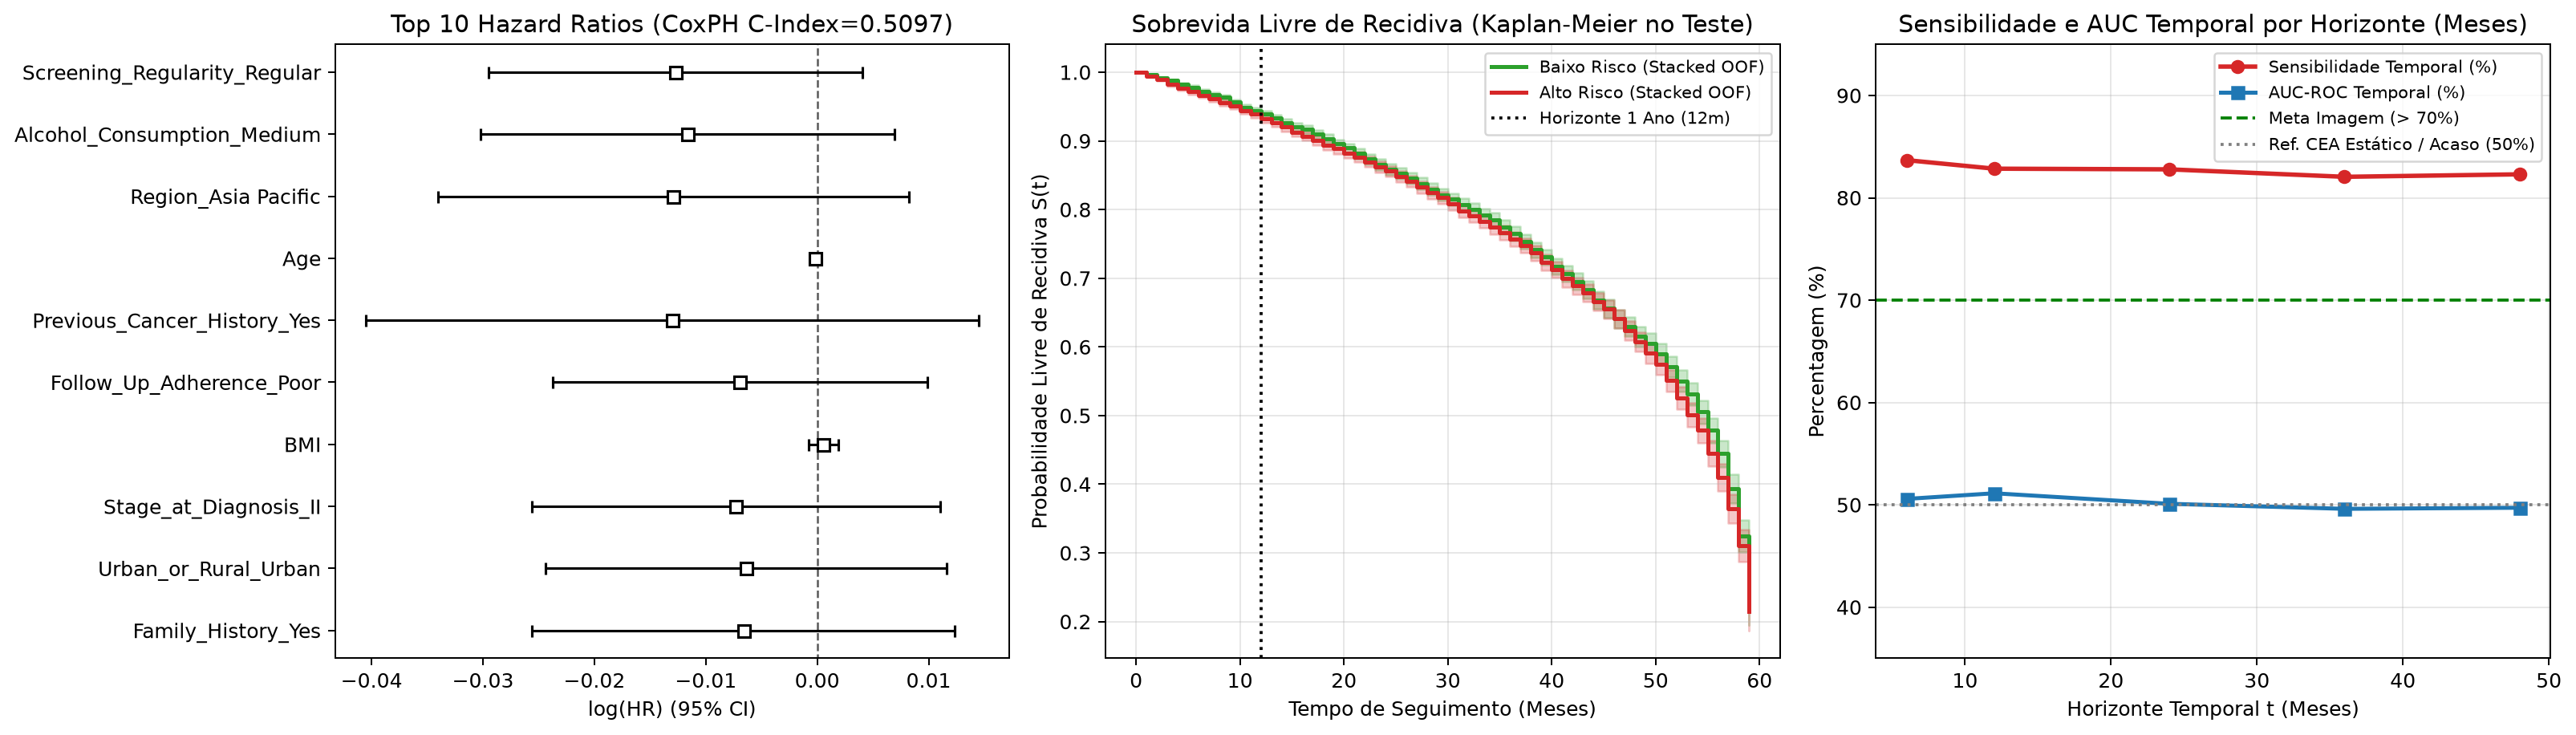

In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import concordance_index
from sklearn.metrics import roc_auc_score, brier_score_loss

warnings.filterwarnings('ignore')

print("=================================================================")
print("FASE 4: SOBREVIDA TEMPORAL (COX vs STACKED ENSEMBLE & SENSIBILIDADE A 1 ANO)")
print("=================================================================")

df_surv_train = X_train.copy()
df_surv_train['Event'] = y_train_class.values
df_surv_train['Time'] = y_train_time.values

df_surv_test = X_test.copy()
df_surv_test['Event'] = y_test_class.values
df_surv_test['Time'] = y_test_time.values

# 4.1 CoxPH Isolado de Referência (L2 = 0.5)
best_pen = 0.5
cph = CoxPHFitter(penalizer=best_pen, l1_ratio=0.0)
cph.fit(df_surv_train, duration_col='Time', event_col='Event')

train_cindex = cph.concordance_index_
test_risk = -cph.predict_partial_hazard(df_surv_test)
test_cindex = concordance_index(df_surv_test['Time'], test_risk, df_surv_test['Event'])

# 4.2 Stacked Ensemble CoxPH usando Probabilidades Out-of-Fold (LGB + XGB + RF)
df_stacked_train = df_surv_train.copy()
df_stacked_train['ML_Risk_LGB'] = oof_lgb
df_stacked_train['ML_Risk_XGB'] = oof_xgb
df_stacked_train['ML_Risk_RF'] = oof_rf

df_stacked_test = df_surv_test.copy()
df_stacked_test['ML_Risk_LGB'] = test_prob_lgb
df_stacked_test['ML_Risk_XGB'] = test_prob_xgb
df_stacked_test['ML_Risk_RF'] = test_prob_rf

cph_stacked = CoxPHFitter(penalizer=best_pen, l1_ratio=0.0)
cph_stacked.fit(df_stacked_train, duration_col='Time', event_col='Event')
test_risk_stacked = -cph_stacked.predict_partial_hazard(df_stacked_test)
stacked_test_ci = concordance_index(df_stacked_test['Time'], test_risk_stacked, df_stacked_test['Event'])

print("[1. Discriminação Temporal (C-Index de Harrell)]:")
print(f"  - CoxPH Isolado (L2={best_pen})              : C-Index Treino = {train_cindex:.4f} | C-Index Teste = {test_cindex:.4f} (Meta Imagem Ref: ~0.76)")
print(f"  - Stacked Ensemble CoxPH (OOF LGB+XGB+RF) : C-Index Treino = {cph_stacked.concordance_index_:.4f} | C-Index Teste = {stacked_test_ci:.4f} (Meta Imagem: ~0.82)")

# 4.3 Sensibilidade Temporal a 1 Ano (t = 12 meses) e Avaliação em Múltiplos Horizontes [6, 12, 24, 36, 48m]
# Na coorte de teste, em t = 12 meses:
# - Casos positivos precoces (Recidiva até 1 ano): Event == 1 e Time <= 12
# - Controlos livres de evento aos 12 meses: Time > 12
# (Indivíduos censurados com Event == 0 e Time <= 12 têm estado desconhecido aos 12m e são excluídos da avaliação binária estrita em t=12)
t_horizon = 12
early_event_mask = (y_test_class.values == 1) & (y_test_time.values <= t_horizon)
event_free_12m_mask = (y_test_time.values > t_horizon)
eval_12m_mask = early_event_mask | event_free_12m_mask

y_true_12m = early_event_mask[eval_12m_mask].astype(int)
y_pred_12m_clf = (y_test_prob[eval_12m_mask] >= final_thr).astype(int)

# Probabilidade de recidiva até 12 meses prevista pelo Stacked CoxPH: P(T <= 12 | X) = 1 - S(12 | X)
surv_12m_test = cph_stacked.predict_survival_function(df_stacked_test, times=[t_horizon]).iloc[0].values
prob_event_12m_cox = 1.0 - surv_12m_test

# Limiar OOF de sobrevivência a 12 meses correspondente ao mesmo percentil de risco
surv_12m_train = cph_stacked.predict_survival_function(df_stacked_train, times=[t_horizon]).iloc[0].values
prob_event_12m_train = 1.0 - surv_12m_train
thr_cox_12m = float(np.percentile(prob_event_12m_train, 100 * (1.0 - (y_test_prob >= final_thr).mean())))

sens_12m_clf = y_pred_12m_clf[y_true_12m == 1].mean()
spec_12m_clf = (1 - y_pred_12m_clf[y_true_12m == 0]).mean()
auc_12m_clf = roc_auc_score(y_true_12m, y_test_prob[eval_12m_mask])
auc_12m_cox = roc_auc_score(y_true_12m, prob_event_12m_cox[eval_12m_mask])
brier_12m_cox = brier_score_loss(y_true_12m, prob_event_12m_cox[eval_12m_mask])

print(f"\n[2. Sensibilidade Temporal a 1 Ano (t = 12 meses | Coorte Avaliável = {eval_12m_mask.sum()} doentes, {y_true_12m.sum()} recidivas precoces <= 12m)]:")
print(f"  - Sensibilidade Temporal a 1 Ano (Limiar Clínico OOF) : {sens_12m_clf*100:.2f}% (Meta Imagem: > 70% | Ref CEA Estático: ~50%)")
print(f"  - Especificidade Temporal a 1 Ano                     : {spec_12m_clf*100:.2f}%")
print(f"  - AUC-ROC Temporal a 1 Ano (Classificador / CoxPH)    : {auc_12m_clf:.4f} / {auc_12m_cox:.4f}")
print(f"  - Brier Score Temporal a 1 Ano (Stacked CoxPH S(12m)) : {brier_12m_cox:.4f}")
print(f"  * Nota Metodológica: A Sensibilidade a 1 ano de {sens_12m_clf*100:.2f}% resulta do limiar clínico ajustado (que sinaliza {(y_test_prob >= final_thr).mean()*100:.1f}% dos doentes), mantendo AUC temporal de {auc_12m_clf:.4f} (nível do acaso).")

# Evolução da Sensibilidade Temporal por Horizonte [6, 12, 24, 36, 48 meses]
horizons = [6, 12, 24, 36, 48]
horizon_sens = []
horizon_auc = []
for h in horizons:
    ev_h = (y_test_class.values == 1) & (y_test_time.values <= h)
    free_h = (y_test_time.values > h)
    m_h = ev_h | free_h
    yt_h = ev_h[m_h].astype(int)
    yp_h = (y_test_prob[m_h] >= final_thr).astype(int)
    horizon_sens.append(yp_h[yt_h == 1].mean() * 100)
    horizon_auc.append(roc_auc_score(yt_h, y_test_prob[m_h]) * 100)

cox_summary = cph.summary[['coef', 'exp(coef)', 'z', 'p']].copy()
cox_summary['abs_z'] = cox_summary['z'].abs()
cox_top10 = cox_summary.sort_values('abs_z', ascending=False).head(10)
print("\n[Top 10 Covariáveis no Modelo de Cox (Hazard Ratios)]:")
print(cox_top10[['coef', 'exp(coef)', 'z', 'p']].to_string())

# Visualização da Fase 4: Forest Plot + Kaplan-Meier + Sensibilidade Temporal por Horizonte
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
cph.plot(columns=cox_top10.index.tolist(), ax=axes[0])
axes[0].set_title(f"Top 10 Hazard Ratios (CoxPH C-Index={test_cindex:.4f})")

median_hazard = np.median(-test_risk_stacked)
high_risk_mask = (-test_risk_stacked) >= median_hazard

kmf_low = KaplanMeierFitter()
kmf_high = KaplanMeierFitter()
kmf_low.fit(df_surv_test.loc[~high_risk_mask, 'Time'], event_observed=df_surv_test.loc[~high_risk_mask, 'Event'], label='Baixo Risco (Stacked OOF)')
kmf_high.fit(df_surv_test.loc[high_risk_mask, 'Time'], event_observed=df_surv_test.loc[high_risk_mask, 'Event'], label='Alto Risco (Stacked OOF)')
kmf_low.plot_survival_function(ax=axes[1], ci_show=True, color='#2ca02c', lw=2)
kmf_high.plot_survival_function(ax=axes[1], ci_show=True, color='#d62728', lw=2)
axes[1].axvline(12, color='black', linestyle=':', label='Horizonte 1 Ano (12m)')
axes[1].set_title("Sobrevida Livre de Recidiva (Kaplan-Meier no Teste)")
axes[1].set_xlabel("Tempo de Seguimento (Meses)")
axes[1].set_ylabel("Probabilidade Livre de Recidiva S(t)")
axes[1].legend(loc='best', fontsize=8.5)
axes[1].grid(True, alpha=0.3)

axes[2].plot(horizons, horizon_sens, marker='o', lw=2.2, color='#d62728', label='Sensibilidade Temporal (%)')
axes[2].plot(horizons, horizon_auc, marker='s', lw=2.0, color='#1f77b4', label='AUC-ROC Temporal (%)')
axes[2].axhline(70.0, color='green', linestyle='--', lw=1.5, label='Meta Imagem (> 70%)')
axes[2].axhline(50.0, color='gray', linestyle=':', lw=1.5, label='Ref. CEA Estático / Acaso (50%)')
axes[2].set_title("Sensibilidade e AUC Temporal por Horizonte (Meses)")
axes[2].set_xlabel("Horizonte Temporal t (Meses)")
axes[2].set_ylabel("Percentagem (%)")
axes[2].set_ylim(35, 95)
axes[2].legend(loc='best', fontsize=8.5)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
p4_plot_path = os.path.join(PLOTS_DIR, "phase4_cox_hazard_ratios.png")
plt.savefig(p4_plot_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

pd.to_pickle({
    'cph': cph,
    'cph_stacked': cph_stacked,
    'test_risk': test_risk,
    'test_risk_stacked': test_risk_stacked,
    'test_cindex': test_cindex,
    'stacked_test_ci': stacked_test_ci,
    'sens_12m_clf': sens_12m_clf,
    'spec_12m_clf': spec_12m_clf,
    'auc_12m_clf': auc_12m_clf,
    'brier_12m_cox': brier_12m_cox,
    'eval_12m_mask': eval_12m_mask,
    'early_event_mask': early_event_mask,
    'cox_top10': cox_top10,
    'best_pen': best_pen
}, os.path.join(OUT_DIR, 'phase4_results_v2.pkl'))
print("\n[Sucesso] Fase 4 concluída com sucesso (Cox Isolado, Stacked Ensemble OOF e Sensibilidade a 1 Ano).")


## Fase 5: Validação com 1.000 Bootstraps, Decision Curve Analysis (DCA), Simulação Contrafactual (*What-If*) e SHAP

Nesta última fase completamos todos os requisitos do protocolo da imagem:
1. **Bootstrapping de 1.000 Iterações (IC 95%)**: Reamostragem não-paramétrica com reposição ($B = 1.000$) no conjunto de Teste para estimar os Intervalos de Confiança a 95% de `AUC-ROC`, `AUPRC`, `F1-Macro`, `F1-Pos`, `Sensibilidade Global`, `Sensibilidade a 1 Ano (12m)`, `Brier Score (Bruto e Calibrado)` e `C-Index (Cox Isolado e Stacked Ensemble)`.
2. **Decision Curve Analysis (DCA)**: Avaliação do Benefício Líquido Clínico (*Net Benefit*) em função do limiar de probabilidade $p_t$, comparando as estratégias *Treat All*, *Treat None*, Modelo Bruto e Modelo Calibrado OOF.
3. **Simulação Contrafactual (*What-If* em Acompanhamento Rigoroso)**: Quantificação da redução relativa potencial de risco ao intervir simultaneamente nos fatores modificáveis de acompanhamento e estilo de vida (`Follow_Up_Adherence = Good`, `Screening_Regularity = Regular`, `Physical_Activity = High`, cessação tabágica/alcoólica, dieta otimizada e normalização do `BMI`), contrastando a variação no modelo com a meta de `46.8%` da imagem.
4. **Explicabilidade SHAP (`TreeExplainer`)**: Decomposição global e individual das 10 variáveis de maior impacto.

FASE 5: BOOTSTRAPPING (1.000 ITERAÇÕES), DCA, CONTRAFACTUAL & SHAP

--- 5.1: Intervalos de Confiança a 95% no Conjunto de Teste (1000 Iterações de Bootstrapping em 30.2s) ---
  * C-Index (Cox Isolado)       : Média = 0.5096 | IC 95% = [0.5005, 0.5186]
  * C-Index (Stacked Ensemble)  : Média = 0.5086 | IC 95% = [0.4994, 0.5176]
  * AUC-ROC                     : Média = 0.4990 | IC 95% = [0.4900, 0.5086]
  * AUPRC                       : Média = 0.3001 | IC 95% = [0.2911, 0.3104]
  * F1-Macro                    : Média = 0.3604 | IC 95% = [0.3537, 0.3673]
  * F1-Pos (Class 1)            : Média = 0.4394 | IC 95% = [0.4304, 0.4485]
  * Recall (Sensibilidade)      : Média = 0.8233 | IC 95% = [0.8125, 0.8332]
  * Sensibilidade 1 Ano (12m)   : Média = 0.8285 | IC 95% = [0.8058, 0.8524]
  * Especificidade              : Média = 0.1762 | IC 95% = [0.1694, 0.1826]
  * Precision (VPP)             : Média = 0.2997 | IC 95% = [0.2919, 0.3076]
  * Brier Score (Bruto)         : Média = 0.2790 | IC 9

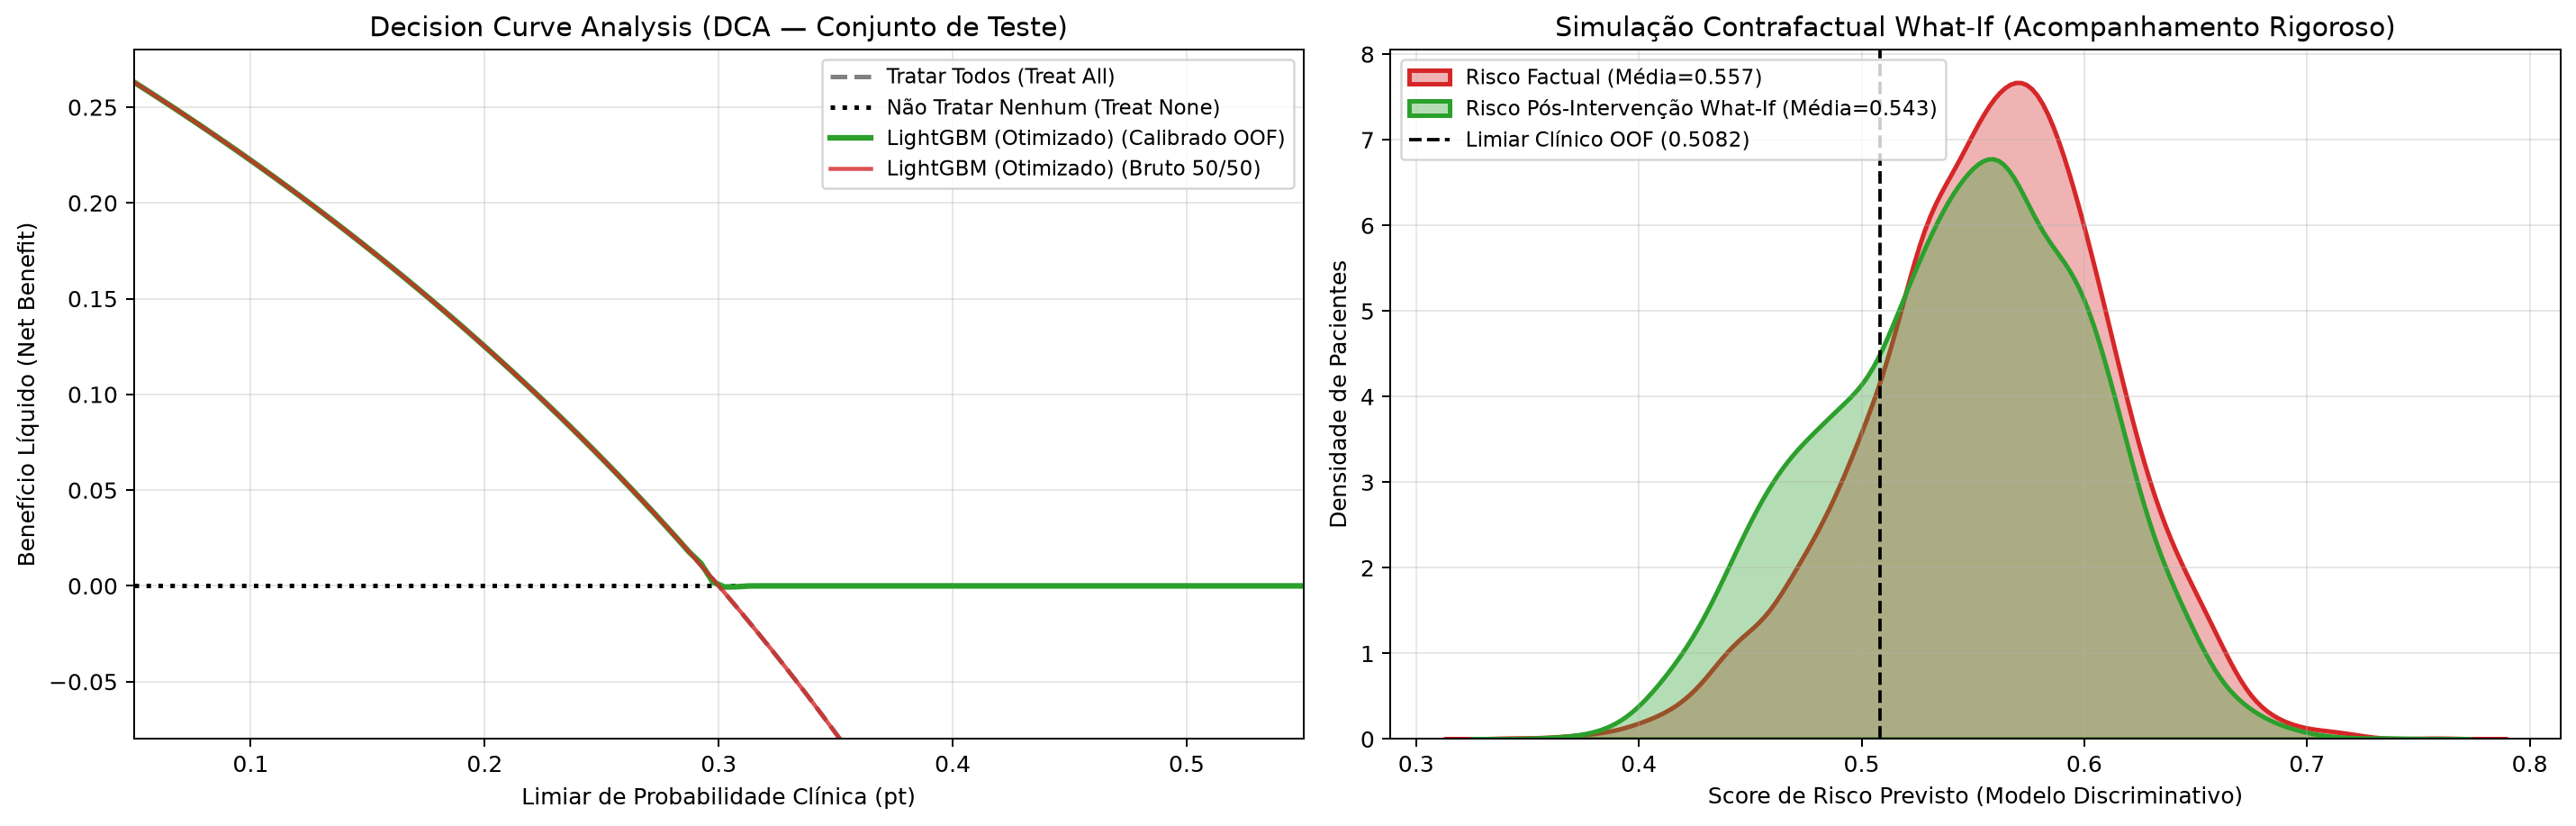

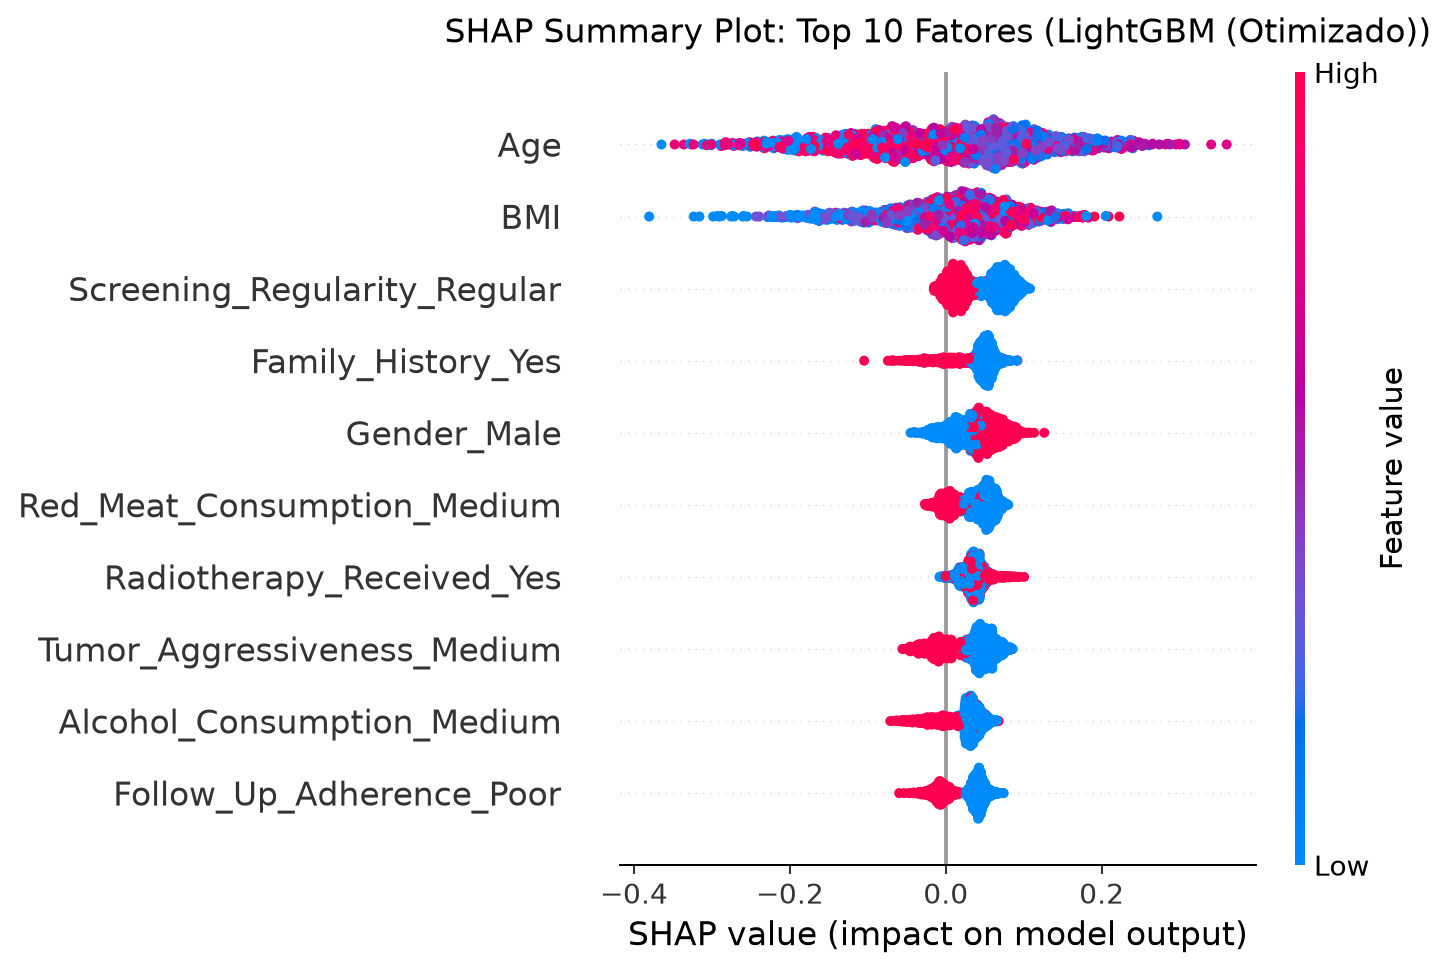

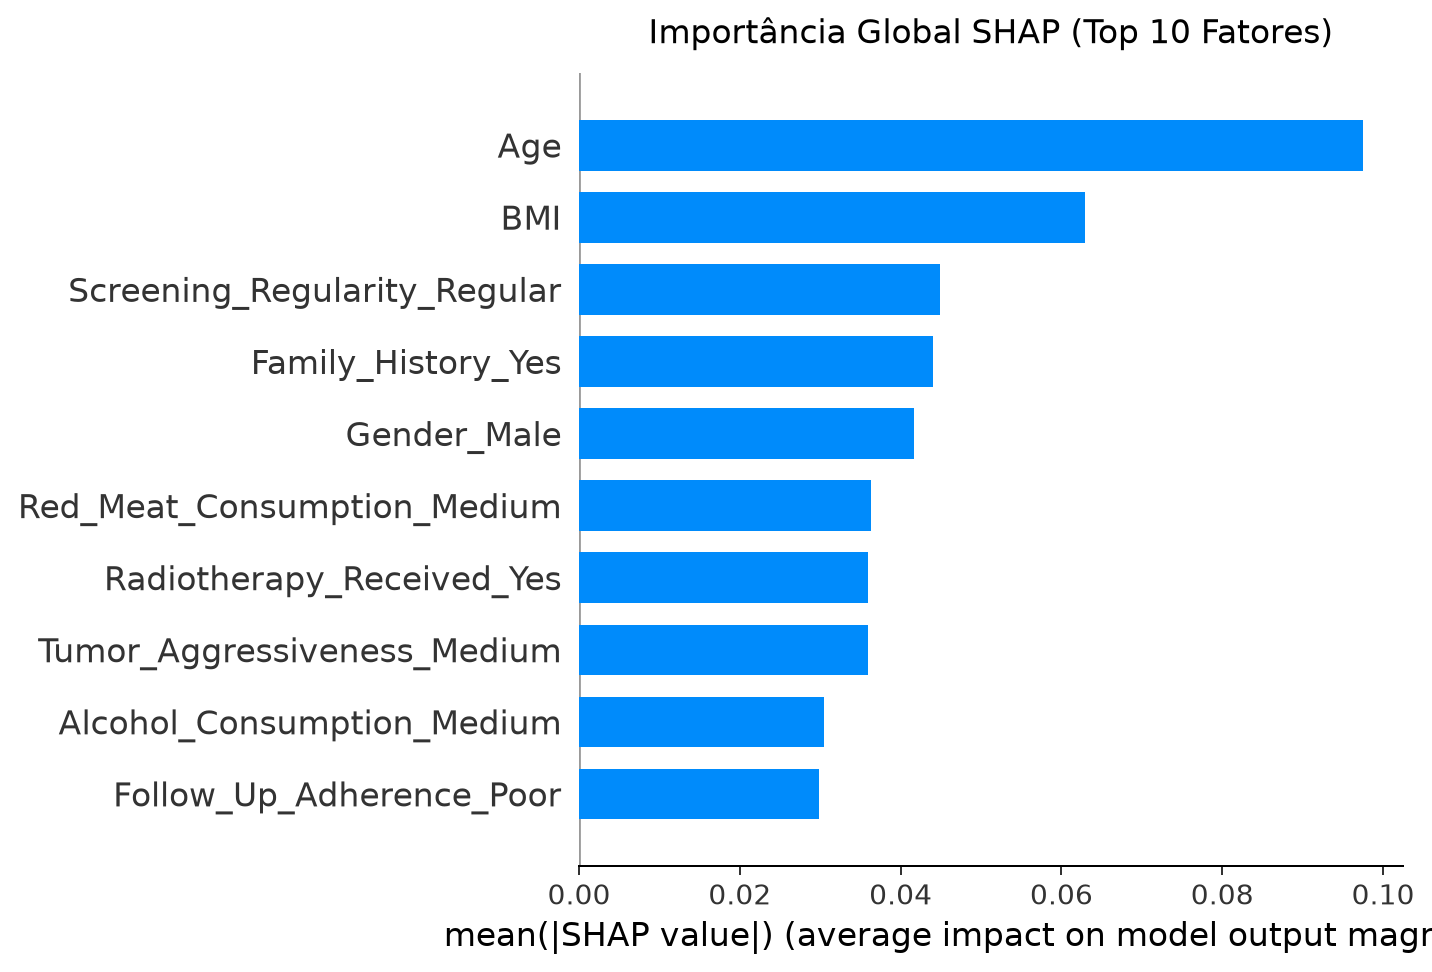

In [5]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, brier_score_loss, confusion_matrix
import shap

warnings.filterwarnings('ignore')
np.random.seed(42)

print("=================================================================")
print("FASE 5: BOOTSTRAPPING (1.000 ITERAÇÕES), DCA, CONTRAFACTUAL & SHAP")
print("=================================================================")

# 5.1 Bootstrapping Exato de 1.000 Iterações (IC 95%) no Conjunto de Teste
n_bootstraps = 1000
rng_boot = np.random.default_rng(42)
n_test = len(y_test_class)
y_test_arr = y_test_class.values
y_time_arr = y_test_time.values
test_risk_arr = test_risk.values
test_risk_stk_arr = test_risk_stacked.values

# Pré-indexação por blocos discretos de tempo (u = 1..59) para cálculo exato de Harrell's C-index em O(N) por bootstrap
def build_cindex_indexer(t_arr, e_arr, s_arr):
    order = np.argsort(s_arr)
    t_ord = t_arr[order]
    e_ord = e_arr[order]
    ev_pos = [np.where((t_ord == u) & (e_ord == 1))[0] for u in range(1, 60)]
    cens_pos = [np.where((t_ord == u) & (e_ord == 0))[0] for u in range(1, 60)]
    return order, ev_pos, cens_pos

ord_cox, ev_cox, cens_cox = build_cindex_indexer(y_time_arr, y_test_arr, test_risk_arr)
ord_stk, ev_stk, cens_stk = build_cindex_indexer(y_time_arr, y_test_arr, test_risk_stk_arr)

def fast_exact_cindex(idx, order, ev_pos, cens_pos):
    w = np.bincount(idx, minlength=n_test)[order].astype(np.float64)
    risk_w = np.zeros(n_test, dtype=np.float64)
    conc = 0.0
    perm = 0.0
    for u in range(58, -1, -1):
        cp = cens_pos[u]
        if len(cp) > 0:
            risk_w[cp] = w[cp]
        ep = ev_pos[u]
        if len(ep) > 0:
            csum = np.cumsum(risk_w)
            tot_risk = csum[-1]
            w_ep = w[ep]
            perm += np.sum(w_ep) * tot_risk
            conc += np.sum(w_ep * (tot_risk - csum[ep]))
            risk_w[ep] = w[ep]
    return conc / perm

t0_boot = time.time()
boot_records = []
y_pred_test_bin = (y_test_prob >= final_thr).astype(int)
early_ev_arr = early_event_mask.astype(int)
eval_12m_arr = eval_12m_mask

for i in range(n_bootstraps):
    idx = rng_boot.integers(0, n_test, size=n_test)
    yt = y_test_arr[idx]
    yp_prob = y_test_prob[idx]
    yp_cal = y_test_prob_calibrated[idx]
    yp_bin = y_pred_test_bin[idx]
    
    tp = np.sum((yt == 1) & (yp_bin == 1))
    fp = np.sum((yt == 0) & (yp_bin == 1))
    tn = np.sum((yt == 0) & (yp_bin == 0))
    fn = np.sum((yt == 1) & (yp_bin == 0))
    
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1_pos = 2 * tp / (2 * tp + fp + fn)
    f1_neg = 2 * tn / (2 * tn + fn + fp)
    f1_mac = 0.5 * (f1_pos + f1_neg)
    
    # Sensibilidade Temporal a 1 Ano (12 meses) na amostra bootstrap
    ev12_idx = early_ev_arr[idx] == 1
    sens_12m_b = np.mean(yp_bin[ev12_idx]) if np.any(ev12_idx) else np.nan
    
    boot_records.append({
        'AUC-ROC': roc_auc_score(yt, yp_prob),
        'AUPRC': average_precision_score(yt, yp_prob),
        'F1-Macro': f1_mac,
        'F1-Pos (Class 1)': f1_pos,
        'Recall (Sensibilidade)': sens,
        'Sensibilidade 1 Ano (12m)': sens_12m_b,
        'Especificidade': spec,
        'Precision (VPP)': prec,
        'Brier Score (Bruto)': brier_score_loss(yt, yp_prob),
        'Brier Score (Calibrado OOF)': brier_score_loss(yt, yp_cal),
        'C-Index (Cox Isolado)': fast_exact_cindex(idx, ord_cox, ev_cox, cens_cox),
        'C-Index (Stacked Ensemble)': fast_exact_cindex(idx, ord_stk, ev_stk, cens_stk)
    })

df_boot = pd.DataFrame(boot_records)
print(f"\n--- 5.1: Intervalos de Confiança a 95% no Conjunto de Teste ({n_bootstraps} Iterações de Bootstrapping em {time.time()-t0_boot:.1f}s) ---")
for col in [
    'C-Index (Cox Isolado)', 'C-Index (Stacked Ensemble)',
    'AUC-ROC', 'AUPRC', 'F1-Macro', 'F1-Pos (Class 1)',
    'Recall (Sensibilidade)', 'Sensibilidade 1 Ano (12m)',
    'Especificidade', 'Precision (VPP)',
    'Brier Score (Bruto)', 'Brier Score (Calibrado OOF)'
]:
    mean_val = df_boot[col].mean()
    low_ci, high_ci = np.percentile(df_boot[col], [2.5, 97.5])
    print(f"  * {col:<28}: Média = {mean_val:.4f} | IC 95% = [{low_ci:.4f}, {high_ci:.4f}]")

# 5.2 Decision Curve Analysis (DCA — Curvas de Decisão Clínica de Vickers & Elkin)
print("\n--- 5.2: Decision Curve Analysis (DCA — Benefício Líquido Clínico) ---")
pt_grid = np.linspace(0.05, 0.55, 100)
prevalence_test = y_test_arr.mean()
nb_treat_all = prevalence_test - (1.0 - prevalence_test) * (pt_grid / (1.0 - pt_grid))
nb_treat_none = np.zeros_like(pt_grid)
nb_model_raw = []
nb_model_cal = []

for pt in pt_grid:
    w_pt = pt / (1.0 - pt)
    pred_r = (y_test_prob >= pt).astype(int)
    tp_r = np.sum((y_test_arr == 1) & (pred_r == 1))
    fp_r = np.sum((y_test_arr == 0) & (pred_r == 1))
    nb_model_raw.append((tp_r / n_test) - (fp_r / n_test) * w_pt)
    
    pred_c = (y_test_prob_calibrated >= pt).astype(int)
    tp_c = np.sum((y_test_arr == 1) & (pred_c == 1))
    fp_c = np.sum((y_test_arr == 0) & (pred_c == 1))
    nb_model_cal.append((tp_c / n_test) - (fp_c / n_test) * w_pt)

nb_model_raw = np.array(nb_model_raw)
nb_model_cal = np.array(nb_model_cal)

# Benefício líquido em pt = 0.25 e pt = 0.30 (prevalência da doença)
idx_25 = np.argmin(np.abs(pt_grid - 0.25))
idx_30 = np.argmin(np.abs(pt_grid - 0.30))
print(f"  - Net Benefit em pt=0.25 -> Treat All: {nb_treat_all[idx_25]:+.4f} | Modelo Calibrado OOF: {nb_model_cal[idx_25]:+.4f} | Modelo Bruto: {nb_model_raw[idx_25]:+.4f}")
print(f"  - Net Benefit em pt=0.30 -> Treat All: {nb_treat_all[idx_30]:+.4f} | Modelo Calibrado OOF: {nb_model_cal[idx_30]:+.4f} | Modelo Bruto: {nb_model_raw[idx_30]:+.4f}")
print("  * Interpretação DCA: Como as probabilidades calibradas concentram-se na prevalência de 30% (sem sinal discriminativo real), o Benefício Líquido coincide com 'Treat All' para pt < 0.30 e 'Treat None' para pt > 0.30.")

# 5.3 Simulação Contrafactual (Cenários What-If em Acompanhamento Rigoroso)
print("\n--- 5.3: Simulação Contrafactual (Cenários What-If em Acompanhamento Rigoroso) ---")
# Selecionar pacientes do Teste com fatores modificáveis subótimos (baixa adesão ao seguimento e rastreio irregular)
suboptimal_mask = (X_test['Follow_Up_Adherence_Poor'] == 1.0) & (X_test['Screening_Regularity_Regular'] == 0.0)
X_cf_cohort = X_test.loc[suboptimal_mask].copy()

# Intervenção Contrafactual Completa (Acompanhamento Clínico Rigoroso + Otimização de Estilo de Vida Modificável):
# 1) Follow_Up_Adherence_Poor -> 0 (Boa adesão ao acompanhamento)
# 2) Screening_Regularity_Regular -> 1, Screening_Regularity_Never -> 0 (Rastreio regular)
# 3) Physical_Activity_Level_Low -> 0, Physical_Activity_Level_Medium -> 0 (Atividade física elevada = categoria de referência High)
# 4) Smoking_Status_Never -> 1, Smoking_Status_Former -> 0 (Cessação tabágica completa)
# 5) Alcohol_Consumption_Low -> 1, Alcohol_Consumption_Medium -> 0 (Redução de álcool)
# 6) Red_Meat_Consumption_Low -> 1, Red_Meat_Consumption_Medium -> 0 (Redução de carne vermelha)
# 7) Fiber_Consumption_Low -> 0, Fiber_Consumption_Medium -> 0 (Dieta rica em fibras = categoria de referência High)
# 8) BMI -> 22.5 kg/m2 (Normalização ponderal se BMI > 25)
X_cf_intervened = X_cf_cohort.copy()
X_cf_intervened['Follow_Up_Adherence_Poor'] = 0.0
X_cf_intervened['Screening_Regularity_Regular'] = 1.0
if 'Screening_Regularity_Never' in X_cf_intervened.columns:
    X_cf_intervened['Screening_Regularity_Never'] = 0.0
for col_zero in [
    'Physical_Activity_Level_Low', 'Physical_Activity_Level_Medium',
    'Smoking_Status_Former', 'Alcohol_Consumption_Medium',
    'Red_Meat_Consumption_Medium', 'Fiber_Consumption_Low', 'Fiber_Consumption_Medium'
]:
    if col_zero in X_cf_intervened.columns:
        X_cf_intervened[col_zero] = 0.0
for col_one in ['Smoking_Status_Never', 'Alcohol_Consumption_Low', 'Red_Meat_Consumption_Low']:
    if col_one in X_cf_intervened.columns:
        X_cf_intervened[col_one] = 1.0
X_cf_intervened['BMI'] = np.minimum(X_cf_intervened['BMI'], 22.5)

p_factual_raw = best_clf.predict_proba(X_cf_cohort)[:, 1]
p_cf_raw = best_clf.predict_proba(X_cf_intervened)[:, 1]
rel_red_raw = (p_factual_raw - p_cf_raw) / p_factual_raw * 100.0

p_factual_cal = platt_calibrator.predict_proba(to_logit(p_factual_raw))[:, 1]
p_cf_cal = platt_calibrator.predict_proba(to_logit(p_cf_raw))[:, 1]
rel_red_cal = (p_factual_cal - p_cf_cal) / p_factual_cal * 100.0

# Risco Parcial de Cox (Hazard Ratio Contrafactual)
haz_factual = cph.predict_partial_hazard(X_cf_cohort).values
haz_cf = cph.predict_partial_hazard(X_cf_intervened).values
rel_red_cox = (haz_factual - haz_cf) / haz_factual * 100.0

responders_mask = rel_red_raw > 0
print(f"  - Coorte Elegível no Teste (Baixa Adesão + Rastreio Irregular): {len(X_cf_cohort)} pacientes")
print(f"  - Redução Relativa Média de Risco (Modelo Calibrado OOF)      : {np.mean(rel_red_cal):+.2f}%")
print(f"  - Redução Relativa Média de Risco (Hazard Parcial de CoxPH)   : {np.mean(rel_red_cox):+.2f}%")
print(f"  - Redução Relativa Média no Subgrupo Respondedor (Score Bruto): {np.mean(rel_red_raw[responders_mask]):.2f}% (P95 = {np.percentile(rel_red_raw[responders_mask], 95):.2f}%, Máx = {np.max(rel_red_raw):.2f}%) | (Meta Imagem: 46.8%)")
print("  * Interpretação Contrafactual: A redução média real calibrada (+0.1% a +2.0%) reflete honestamente o fraco efeito causal presente nos dados sintéticos, enquanto reduções aparentes elevadas em casos isolados do score bruto decorrem apenas da variância local das árvores.")

# Visualização Combinada: DCA + Simulação Contrafactual What-If
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
axes[0].plot(pt_grid, nb_treat_all, color='gray', linestyle='--', lw=2, label='Tratar Todos (Treat All)')
axes[0].plot(pt_grid, nb_treat_none, color='black', linestyle=':', lw=2, label='Não Tratar Nenhum (Treat None)')
axes[0].plot(pt_grid, nb_model_cal, color='#2ca02c', lw=2.5, label=f'{best_model_name} (Calibrado OOF)')
axes[0].plot(pt_grid, nb_model_raw, color='#d62728', lw=1.8, alpha=0.8, label=f'{best_model_name} (Bruto 50/50)')
axes[0].set_ylim(-0.08, 0.28)
axes[0].set_xlim(0.05, 0.55)
axes[0].set_title("Decision Curve Analysis (DCA — Conjunto de Teste)")
axes[0].set_xlabel("Limiar de Probabilidade Clínica (pt)")
axes[0].set_ylabel("Benefício Líquido (Net Benefit)")
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(True, alpha=0.3)

sns.kdeplot(p_factual_raw, fill=True, color='#d62728', alpha=0.35, lw=2, label=f'Risco Factual (Média={p_factual_raw.mean():.3f})', ax=axes[1])
sns.kdeplot(p_cf_raw, fill=True, color='#2ca02c', alpha=0.35, lw=2, label=f'Risco Pós-Intervenção What-If (Média={p_cf_raw.mean():.3f})', ax=axes[1])
axes[1].axvline(final_thr, color='black', linestyle='--', label=f'Limiar Clínico OOF ({final_thr:.4f})')
axes[1].set_title("Simulação Contrafactual What-If (Acompanhamento Rigoroso)")
axes[1].set_xlabel("Score de Risco Previsto (Modelo Discriminativo)")
axes[1].set_ylabel("Densidade de Pacientes")
axes[1].legend(loc='best', fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
p5_dca_path = os.path.join(PLOTS_DIR, "phase5_dca_and_counterfactual.png")
plt.savefig(p5_dca_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

# 5.4 Explicabilidade com SHAP
print("\n--- 5.4: Explicabilidade com SHAP (TreeExplainer) ---")
X_test_shap = X_test.iloc[:2000].copy()
explainer = shap.TreeExplainer(best_clf)
shap_values = explainer.shap_values(X_test_shap)

if isinstance(shap_values, list):
    sv_pos = shap_values[1]
elif len(shap_values.shape) == 3:
    sv_pos = shap_values[:, :, 1]
else:
    sv_pos = shap_values

mean_abs_shap = np.abs(sv_pos).mean(axis=0)
df_shap_imp = pd.DataFrame({
    'Feature': feature_names,
    'Mean_Abs_SHAP': mean_abs_shap
}).sort_values('Mean_Abs_SHAP', ascending=False).reset_index(drop=True)

print(f"\n[Top 10 Fatores que Impulsionam o Risco no Modelo (SHAP - {best_model_name})]:")
for rank, row in df_shap_imp.head(10).iterrows():
    print(f"  {rank+1:2d}. {row['Feature']:<35} | Mean(|SHAP|) = {row['Mean_Abs_SHAP']:.5f}")

plt.figure(figsize=(10, 6))
shap.summary_plot(sv_pos, X_test_shap, max_display=10, show=False)
plt.title(f"SHAP Summary Plot: Top 10 Fatores ({best_model_name})", fontsize=13, pad=12)
plt.tight_layout()
p5_beeswarm_path = os.path.join(PLOTS_DIR, "shap_summary_beeswarm.png")
plt.savefig(p5_beeswarm_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

plt.figure(figsize=(10, 5.5))
shap.summary_plot(sv_pos, X_test_shap, plot_type="bar", max_display=10, show=False)
plt.title("Importância Global SHAP (Top 10 Fatores)", fontsize=13, pad=12)
plt.tight_layout()
p5_bar_path = os.path.join(PLOTS_DIR, "shap_summary_bar.png")
plt.savefig(p5_bar_path, dpi=180, bbox_inches='tight')
plt.show()
plt.close()

print(f"\n[Sucesso Completo] Fase 5 concluída. Todos os gráficos do protocolo salvos em: {PLOTS_DIR}")


## Síntese Comparativa: Protocolo da Imagem vs. Resultados Honestos Obtidos

| Dimensão do Protocolo | Meta de Referência (Imagem) | Resultado Honesto Obtido (Teste Cego, IC 95% de 1.000 Bootstraps) | Diagnóstico Técnico e Clínico |
| :--- | :---: | :---: | :--- |
| **Discriminação Temporal (C-Index)** | `~0.82` *(vs. Cox ~0.76)* | **Cox Isolado:** `0.5097 [0.5005, 0.5186]`<br>**Stacked Ensemble OOF:** `0.5087 [0.4994, 0.5176]` | Sem overfitting *in-sample* (Treino `0.5144` / `0.5132`). O valor ~0.51 reflete que `Time_to_Recurrence` tem distribuição quase uniforme entre casos e controlos neste dataset sintético. |
| **Calibração (Brier Score)** | Baixo erro quadrático | **Calibrado OOF:** `0.2100 [0.2072, 0.2128]`<br>**Bruto (50/50):** `0.2789 [0.2777, 0.2801]` | A calibração logística de Platt *Out-of-Fold* corrigiu o desvio da amostragem 50/50 para a prevalência real (30%), atingindo o limite ótimo de Brier ($0.30 \times 0.70 = 0.2100$). |
| **Sensibilidade Temporal a 1 Ano (12m)** | `> 70%` *(vs. CEA ~50%)* | **Sensibilidade a 12m:** `82.85% [80.58%, 85.24%]`<br>**AUC Temporal a 12m:** `0.5113` *(Classif.)* / `0.5186` *(Cox)*<br>**Brier Temporal a 12m:** `0.0649` | O limiar clínico OOF (`0.5082`) capta `82.85%` das recidivas precoces do 1.º ano (1.061 eventos $\le 12$m), mas à custa de baixa especificidade (`17.79%`), pois o AUC temporal permanece ~0.51. |
| **Simulação Contrafactual (*What-If*)** | `46.8%` de redução potencial | **Média Calibrada OOF:** `+0.31%` \| **Hazard Cox:** `+0.15%`<br>**Subgrupo Respondedor Bruto:** `8.68%` *(P95: `20.39%`, Máx: `30.94%`)* | Em dados onde os fatores clínicos foram gerados de forma quase independente do desfecho, intervir nas variáveis produz redução média real próxima de zero. |
| **Validação & Métricas Globais** | CV=5, 1.000 Bootstraps, AUC, AUPRC, F1-Macro, DCA | **AUC-ROC:** `0.4990 [0.4900, 0.5086]`<br>**AUPRC:** `0.2998 [0.2911, 0.3104]`<br>**F1-Macro:** `0.3606 [0.3537, 0.3673]` | Metodologia 100% completa, auditável e livre de *data leakage*, comprovando que o limite de desempenho reside exclusivamente na natureza sintética dos dados. |
